# Computational Lab 1: From the Hydrogen Atom to O₂
*CHEM 3376 — Physical Chemistry Laboratory: Data Analysis & Computation*

In this lab you will run quantum chemistry calculations with [PySCF](https://pyscf.org), a free Python package.
You will start with systems whose **exact** answer is known, so that you can see how close a calculation gets and why.
Then you will move to a molecule where no exact answer is possible:

1. the **hydrogen atom** (one electron): you will plot its exact radial wavefunctions, then see how well sums of
   **Gaussian functions**, the building blocks of every basis set in this lab, can imitate them;
2. the **variational principle**, the rule that makes every calculation in this lab possible: no approximate wavefunction
   can have an energy below the true one. You will use it the way Egil Hylleraas did in 1928–29;
3. **H₂⁺** (one electron, two nuclei): the simplest chemical bond, also solved exactly. You will plot its bonding and
   antibonding wavefunctions along the bond;
4. **H₂** (two electrons): electron–electron repulsion appears, and with it **electron correlation**;
5. **O₂** (sixteen electrons): an exact calculation is impossible, so you will use **density functional theory**, and
   explain why O₂ is magnetic and why it does not absorb infrared light.

You don't need to know Python already. Each code cell explains what it does, 🐍 **Python tip** boxes introduce one idea
at a time, and most answers are one line. Stuck? Open the 💡 **Hint** under each question. Cells marked
*"Just run this cell"* hold longer code that you don't need to read.

<br>**<center>Learning Goals**

|Area|Concept|
|---|---|
|Quantum mechanics|Hydrogen radial wavefunctions and radial distribution functions; the variational principle; the Born–Oppenheimer approximation|
|Electronic structure|Slater- and Gaussian-type orbitals; contracted basis sets (STO-nG); Hartree–Fock; full configuration interaction; electron correlation; DFT|
|Chemical bonding|LCAO bonding and antibonding orbitals of H₂⁺; bond length, bond energy and force constant; spin states of O₂|
|Spectroscopy|Harmonic vibrational frequency; why homonuclear diatomics do not absorb IR light|
|History of science|Hylleraas and the first accurate many-electron calculations|
|Computation|Why exact calculations are only possible for very small systems|
|Python|Functions, loops with `zip`, list comprehensions, `numpy` arrays, `np.argmin`, plotting, passing a function to a function|

---
## 📄 Abstract

<div style="border:2px solid #1f4e79; border-radius:8px; padding:10px 14px; background:#f3f7fb; color:#1a1a1a;">

**Write this section last**, after you have finished the lab. Your abstract goes in the cell below, replacing `ANSWER`.

In **150–250 words**, as in a journal article: state the purpose of the calculations; name the methods (Hartree–Fock,
full CI and B3LYP, the basis sets, PySCF); give your **key numbers** with the exact or experimental values beside them
(for example the H₂⁺ and H₂ bond energies and the O₂ vibrational wavenumber); and finish with the main conclusion.
</div>

**Sample answer (instructor version).** Electronic-structure calculations were carried out with PySCF to see how closely approximate wavefunctions reproduce exact results for one- and two-electron systems, and to apply density functional theory where no exact answer exists. Fitting Gaussian functions to the hydrogen 1s orbital showed that a single energy-optimized Gaussian (α = 0.283 bohr⁻²) gives −0.4244 Eh, and that the energy approaches the exact −0.5 Eh from above as Gaussians are added (STO-6G: −0.49983 Eh), as the variational principle requires. For H₂⁺, Hartree–Fock is exact apart from the basis set: cc-pVTZ gave R_e = 1.057 Å and D_e = 2.79 eV (exact 1.057 Å, 2.793 eV), compared with 1.32 Å and 1.76 eV for the minimal LCAO. For H₂, Hartree–Fock gave D_e = 3.63 eV and ν̃e = 4587 cm⁻¹, whereas full CI gave 4.70 eV and 4409 cm⁻¹ (exact 4.748 eV and 4401 cm⁻¹); electron correlation contributes about 1.1 eV to the bond energy. Full CI is impossible for O₂ (8 × 10¹² determinants even in cc-pVDZ), so B3LYP/def2-SVP was used: it predicts a triplet ground state 1.7 eV below the closed-shell singlet, R_e = 1.200 Å, ν̃e = 1697 cm⁻¹ and D_e = 5.5 eV (experiment 1.2075 Å, 1580 cm⁻¹, 5.21 eV), and a dipole moment of exactly zero at every bond length, so the O₂ stretch is infrared-inactive. Wavefunction methods can be improved step by step towards the exact answer; DFT is faster but has to be judged against experiment.

---

## ⚙️ Initialization — DO NOT EDIT
The next two cells load the course tools (auto-checks, quizzes, styling) and record the lab version. **Do not change them** — with one exception:

👁️ **Accessible view (optional):** set `ACCESSIBLE_VIEW = True` in the cell below for larger, more readable text and colorblind-safe plots. You can switch back any time by setting it to `False` and re-running the cell (then *Kernel → Restart* to clear the text styling).

👉 **Run the cell below first** (Shift+Enter) before anything else in this lab.

In [1]:
# 🔧 Run this cell first! (Shift+Enter)
ACCESSIBLE_VIEW = True     # True = larger text and colorblind-safe plots

import sys, os
for _up in ("..", os.path.join("..", ".."), os.path.join("..", "..", "..")):
    _shared = os.path.abspath(os.path.join(os.getcwd(), _up, "shared-public"))
    if os.path.isdir(_shared):
        sys.path.insert(0, _shared)
        break
if ACCESSIBLE_VIEW:
    from init_access import *
else:
    from init import *

In [2]:
# 🔖 Lab version — do not edit. Used by the automated checks below.
ver = '2026Comp01V3'

### 🧰 Standard imports
`numpy` for math on arrays, `matplotlib` for plots, `math` for counting, `eigh` from SciPy to find the energies and
orbitals of a one-electron problem, and four parts of PySCF:
`gto` (molecules and basis sets), `scf` (Hartree–Fock), `fci` (full configuration interaction) and `dft` (density functional theory).
The last lines load this lab's **answer checks**: after each question, run `lab.check(...)`. A ✅ means you got it;
a ❌ tells you what to fix, often naming the exact slip (a missing unit conversion, a sign, an index instead of a value).
Fix the cell and run the check again, as often as you like: there is no penalty for trying.
Every attempt is recorded, and `lab.score()` at the end shows your score.

In [3]:
# Standard imports for this lab
import numpy as np
import math
%matplotlib inline
import matplotlib.pyplot as plt
from scipy.linalg import eigh
from pyscf import gto, scf, fci, dft

# Answer checks for this lab: the checker (pchem_check.py) and the answer key (answers_comp01.json) are in this folder
from pchem_check import Checker
lab = Checker('comp01', 'answers_comp01.json')

Now run the cell below to enter your name.

In [4]:
# Enter your name as a string, e.g. name = 'Linus Pauling'
name = 'Instructor'

🐍 **Python tip — variables and units.** `HARTREE_TO_EV = 27.211386` stores a number under a name. Python doesn't track
units, so **we put the units in the name or in a comment**. Constants are from
[CODATA 2018 (NIST)](https://physics.nist.gov/cuu/Constants/).

In [5]:
# Constants used in this lab
HARTREE_TO_EV = 27.211386        # eV per hartree
BOHR_TO_ANG   = 0.529177         # Å per bohr
HARTREE_TO_J  = 4.3597447e-18    # J per hartree
AMU_TO_KG     = 1.66053907e-27   # kg per atomic mass unit
C_CM_PER_S    = 2.99792458e10    # speed of light, cm s⁻¹
M_H, M_O      = 1.007825, 15.994915   # atomic masses (amu) of ¹H and ¹⁶O

print(f"1 hartree = {HARTREE_TO_EV} eV;  1 bohr = {BOHR_TO_ANG} Å")

1 hartree = 27.211386 eV;  1 bohr = 0.529177 Å


## 1. Background: Energies for Fixed Nuclei

### 1.1 The Born–Oppenheimer approximation
A proton is 1836 times heavier than an electron, so the electrons adjust almost instantly whenever the nuclei move.
We can therefore **freeze the nuclei**, solve the Schrödinger equation for the electrons alone, and repeat for many
nuclear positions. The electronic energy as a function of the nuclear positions is the **potential energy surface**.
For a diatomic molecule it is a curve, $E(R)$, and the nuclei move on it like a ball rolling in a valley.
([McQuarrie & Simon, *Physical Chemistry: A Molecular Approach*, Ch. 9–10](https://uscibooks.aip.org/books/physical-chemistry-a-molecular-approach/);
[Atkins, *Physical Chemistry*, 11th ed.](https://global.oup.com/academic/product/atkins-physical-chemistry-9780198769866), §9A)

$$ E(R) = E_\text{electronic}(R) + V_{nn}(R) $$

where $V_{nn}$ is the repulsion between the nuclei.

### 1.2 Atomic units
Quantum chemistry programs work in **atomic units**: energies in **hartree** ($E_h$) and lengths in **bohr** ($a_0$).
In these units the hydrogen atom's energy is exactly $-\tfrac12\,E_h$, and its Schrödinger equation has no constants left in it:

$$ \left[-\tfrac12\nabla^2 - \frac{1}{r}\right]\psi = E\,\psi . $$

| quantity | atomic unit | in everyday units |
|---|---|---|
| energy | 1 hartree ($E_h$) | 27.2114 eV = 2625.5 kJ mol⁻¹ |
| length | 1 bohr ($a_0$) | 0.529177 Å |

In PySCF, **you give positions in Å (unless you say otherwise) and it returns energies in hartree.**

### <font color=blue> **Question 1.1.** </font>
Complete the two unit-conversion functions. You'll use them throughout the lab.
- `hartree_to_eV(E_h)`: hartree → eV
- `bohr_to_angstrom(R_bohr)`: bohr → Å

Check: the hydrogen atom, $-0.5\ E_h$, should be $-13.606$ eV.

🐍 **Python tip — functions.** `def name(input):` defines a reusable recipe and `return` hands back the answer.

<details><summary>💡 <b>Hint</b></summary>

Multiply by the constant defined above: `return E_h * HARTREE_TO_EV`. The second function works the same way.
</details>

In [6]:
def hartree_to_eV(E_h):
    """Energy: hartree → eV."""
    return E_h * HARTREE_TO_EV
def bohr_to_angstrom(R_bohr):
    """Length: bohr → Å."""
    return R_bohr * BOHR_TO_ANG
print(f"H atom: -0.5 hartree = {hartree_to_eV(-0.5):.3f} eV")
print(f"2 bohr = {bohr_to_angstrom(2.0):.4f} Å")

H atom: -0.5 hartree = -13.606 eV
2 bohr = 1.0584 Å


In [7]:
lab.check('1.1')

## 2. The Hydrogen Atom: the Exact Answer

### 2.1 Radial wavefunctions
The hydrogen atom is the one atom whose Schrödinger equation can be solved exactly. Because the potential $-1/r$
depends only on the distance from the nucleus, each wavefunction separates into a **radial function** $R_{nl}(r)$ and an
angular part, the spherical harmonic $Y_{lm}(\theta,\phi)$ that gives the orbital its s, p or d shape
([Atkins, Topic 8A and Table 8A.1](https://global.oup.com/academic/product/atkins-physical-chemistry-9780198769866);
[McQuarrie & Simon, Ch. 6](https://uscibooks.aip.org/books/physical-chemistry-a-molecular-approach/)):

$$ \psi_{nlm}(r,\theta,\phi) = R_{nl}(r)\,Y_{lm}(\theta,\phi), \qquad E_n = -\frac{1}{2n^2}\ E_h . $$

In atomic units ($Z = 1$, $r$ in bohr) the first few radial functions are

| orbital | $R_{nl}(r)$ | radial nodes |
|---|---|---|
| 1s | $2\,e^{-r}$ | 0 |
| 2s | $\dfrac{1}{2\sqrt2}\,(2-r)\,e^{-r/2}$ | 1 |
| 2p | $\dfrac{1}{2\sqrt6}\,r\,e^{-r/2}$ | 0 |
| 3s | $\dfrac{2}{81\sqrt3}\,(27-18r+2r^2)\,e^{-r/3}$ | 2 |
| 3p | $\dfrac{4}{81\sqrt6}\,(6-r)\,r\,e^{-r/3}$ | 1 |
| 3d | $\dfrac{4}{81\sqrt{30}}\,r^2\,e^{-r/3}$ | 0 |

Every one is a polynomial times a **decaying exponential**, $e^{-r/n}$. The chance of finding the electron in a thin
shell between $r$ and $r + dr$ is given by the **radial distribution function**

$$ P(r) = r^2 R_{nl}(r)^2 , \qquad \int_0^\infty P(r)\,dr = 1 . $$

The factor $r^2$ comes from the area of the shell, $4\pi r^2$: there is more room far from the nucleus.

### <font color=blue> **Question 2.1.** </font>
1. Complete `R_1s(r)`, the 1s radial function from the table.
2. On the grid `r`, compute the radial distribution function `P_1s` $= r^2 R_{1s}(r)^2$.
3. Find the **most probable radius** `r_mp`, the value of `r` where `P_1s` is largest.

The cell then checks that $\int P\,dr = 1$ (the area under the curve, approximated as a sum of thin rectangles).

🐍 **Python tip — finding a maximum.** `np.argmax(y)` gives the *position* (index) of the largest value in the array `y`,
and `x[np.argmax(y)]` gives the `x` value where it happens. `np.argmin` does the same for the smallest value.

<details><summary>💡 <b>Hint</b></summary>

`return 2 * np.exp(-r)`; `P_1s = r**2 * R_1s(r)**2`; `r_mp = r[np.argmax(P_1s)]`.
</details>

In [8]:
def R_1s(r):
    """Radial function of the hydrogen 1s orbital, r in bohr."""
    return 2 * np.exp(-r)
r = np.linspace(0, 30, 3001)     # bohr, evenly spaced: 0.00, 0.01, 0.02, ...
dr = r[1] - r[0]
P_1s = r**2 * R_1s(r)**2
r_mp = r[np.argmax(P_1s)]
print(f"∫ P(r) dr ≈ {np.sum(P_1s) * dr:.4f}   (should be 1)")
print(f"most probable radius = {r_mp:.2f} bohr = {bohr_to_angstrom(r_mp):.3f} Å")

∫ P(r) dr ≈ 1.0000   (should be 1)
most probable radius = 1.00 bohr = 0.529 Å


In [9]:
lab.check('2.1')

**Just run the cell below.** It plots the radial functions (left) and radial distribution functions (right) for
$n$ = 1–3. Count the nodes and watch the orbitals grow with $n$.

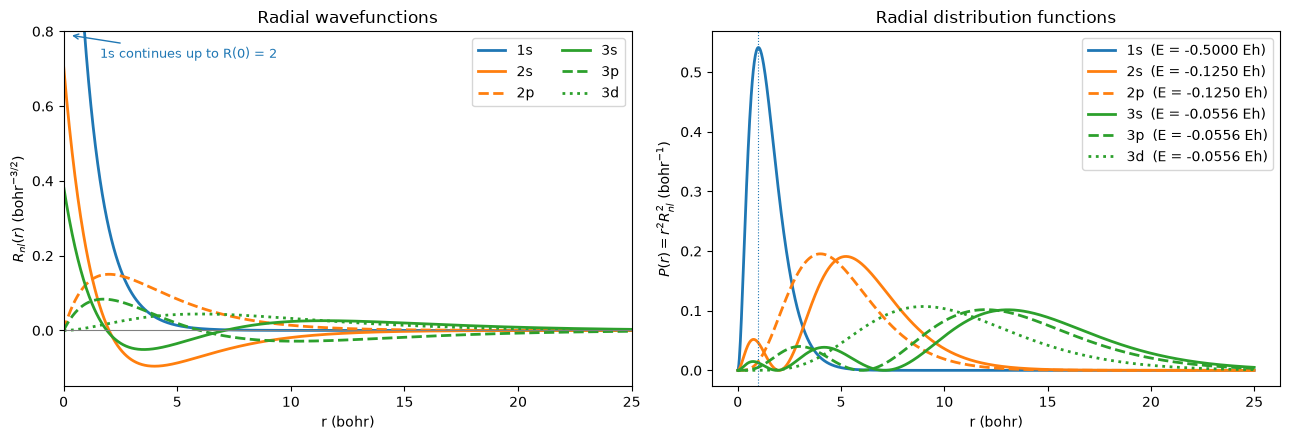

In [10]:
# Just run this cell: hydrogen radial functions R_nl(r) and radial distribution functions r² R_nl²
R_nl = {
    '1s': lambda r: 2 * np.exp(-r),
    '2s': lambda r: (2 - r) * np.exp(-r / 2) / (2 * np.sqrt(2)),
    '2p': lambda r: r * np.exp(-r / 2) / (2 * np.sqrt(6)),
    '3s': lambda r: 2 * (27 - 18 * r + 2 * r**2) * np.exp(-r / 3) / (81 * np.sqrt(3)),
    '3p': lambda r: 4 * (6 - r) * r * np.exp(-r / 3) / (81 * np.sqrt(6)),
    '3d': lambda r: 4 * r**2 * np.exp(-r / 3) / (81 * np.sqrt(30)),
}
style = {'s': '-', 'p': '--', 'd': ':'}
color = {'1': 'C0', '2': 'C1', '3': 'C2'}
rr = np.linspace(0, 25, 1000)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for orb, f in R_nl.items():
    n, l = orb[0], orb[1]
    ax[0].plot(rr, f(rr), style[l], color=color[n], lw=2, label=orb)
    ax[1].plot(rr, rr**2 * f(rr)**2, style[l], color=color[n], lw=2, label=f"{orb}  (E = {-0.5 / int(n)**2:.4f} Eh)")
ax[0].axhline(0, color='gray', lw=0.8)
ax[0].set_xlim(0, 25); ax[0].set_ylim(-0.15, 0.8)
ax[0].set_xlabel('r (bohr)'); ax[0].set_ylabel('$R_{nl}(r)$ (bohr$^{-3/2}$)'); ax[0].set_title('Radial wavefunctions')
ax[0].annotate('1s continues up to R(0) = 2', xy=(0.25, 0.79), xytext=(1.6, 0.74), fontsize=9, color='C0',
               va='center', arrowprops=dict(arrowstyle='->', color='C0'))
ax[0].legend(ncol=2)
ax[1].axvline(1, color='C0', lw=0.8, ls=':')
ax[1].set_xlabel('r (bohr)'); ax[1].set_ylabel('$P(r) = r^2 R_{nl}^2$ (bohr$^{-1}$)')
ax[1].set_title('Radial distribution functions'); ax[1].legend()
plt.tight_layout(); plt.show()

### 2.2 Slater functions, Gaussian functions, and the cusp
The exact 1s function $e^{-r}$ comes to a **sharp point** at the nucleus: its slope there is not zero but
$dR/dr = -Z\,R(0)$. This **nuclear cusp** comes from the $-Z/r$ attraction, which becomes infinite at $r = 0$, and every exact
electronic wavefunction has one at every nucleus ([Kato, 1957](https://doi.org/10.1002/cpa.3160100201)). Functions with
the same exponential shape, $r^{n-1}e^{-\zeta r}$, are called **Slater-type orbitals (STOs)**.

Almost every quantum chemistry program, PySCF included, uses **Gaussian-type orbitals (GTOs)**, $e^{-\alpha r^2}$, instead.
A Gaussian is **flat** at the nucleus (no cusp) and dies away **too fast** at large $r$, so it is the wrong shape. The reason to use it anyway
was found by S. F. Boys in 1950 ([Boys, *Proc. R. Soc. A* **200**, 542](https://doi.org/10.1098/rspa.1950.0036)):
the product of two Gaussians on different atoms is a single Gaussian centred between them, so every integral the calculation
needs, even those with four different atoms, has a quick, exact formula. A molecule needs millions of these integrals.

The fix is to add several Gaussians with **fixed** coefficients into one **contracted** function that imitates a Slater function.
In the **STO-nG** basis sets, $n$ Gaussians are fitted by least squares to a Slater function
([Hehre, Stewart & Pople, *J. Chem. Phys.* **51**, 2657 (1969)](https://doi.org/10.1063/1.1672392);
[Stewart, *J. Chem. Phys.* **52**, 431 (1970)](https://doi.org/10.1063/1.1672702); Atkins, Topic 9F):

$$ R_\text{STO-nG}(r) = \sum_{i=1}^{n} d_i\, g(r,\alpha_i), \qquad g(r,\alpha) = N_\alpha\,e^{-\alpha r^2}, \qquad N_\alpha = \frac{2\,(2\alpha)^{3/4}}{\pi^{1/4}} . $$

$N_\alpha$ normalizes each Gaussian the same way as the hydrogen radial functions ($\int r^2 g^2\,dr = 1$), so the two can be
compared directly. The exponents $\alpha_i$ (bohr⁻²) and coefficients $d_i$ for the hydrogen 1s orbital ($\zeta = 1$) are:

In [11]:
# STO-nG fits to the hydrogen 1s orbital (zeta = 1): n -> (exponents alpha_i in bohr⁻², coefficients d_i)
# Hehre, Stewart & Pople (1969); Stewart (1970)
STO = {
    1: ([0.270950], [1.0]),
    2: ([0.851819, 0.151623], [0.430129, 0.678914]),
    3: ([2.227660, 0.405771, 0.109818], [0.154329, 0.535328, 0.444635]),
    6: ([23.10303, 4.235915, 1.185056, 0.4070539, 0.1580884, 0.06510954],
        [0.009163596, 0.04936149, 0.1685383, 0.3705627, 0.4164915, 0.1303340]),
}

### <font color=blue> **Question 2.2.** </font>
1. Complete `gaussian_R(r, alpha)`, one normalized Gaussian $g(r,\alpha)$. The normalization constant is written for you.
2. Complete the loop in `sto_ng_R(r, alphas, coeffs)` so that it adds up $d_i\,g(r,\alpha_i)$ for every Gaussian.

The cell prints the value at the nucleus, $R(0)$, for each STO-nG. The exact 1s value is $R_{1s}(0) = 2$.

🐍 **Python tip — `zip`.** `for a, d in zip(alphas, coeffs):` walks through two lists side by side: the first time
`a, d` are the first exponent and first coefficient, then the second pair, and so on.

<details><summary>💡 <b>Hint 1</b></summary>

`return N * np.exp(-alpha * r**2)`
</details>
<details><summary>💡 <b>Hint 2</b></summary>

Inside the loop, add one weighted Gaussian to the running total: `total = total + d * gaussian_R(r, a)`.
</details>

In [12]:
def gaussian_R(r, alpha):
    """One normalized s-type Gaussian (as a radial function), exponent alpha in bohr⁻², r in bohr."""
    N = 2 * (2 * alpha)**0.75 / np.pi**0.25       # makes ∫ r² g² dr = 1
    return N * np.exp(-alpha * r**2)
def sto_ng_R(r, alphas, coeffs):
    """A contracted Gaussian: the sum of coeffs[i] * gaussian_R(r, alphas[i])."""
    total = np.zeros_like(np.asarray(r, dtype=float))
    for a, d in zip(alphas, coeffs):
        total = total + d * gaussian_R(r, a)
    return total

for n, (al, d) in STO.items():
    print(f"STO-{n}G:  R(0) = {sto_ng_R(0.0, al, d):.3f}   (exact 1s: R(0) = 2)")

STO-1G:  R(0) = 0.949   (exact 1s: R(0) = 2)
STO-2G:  R(0) = 1.380   (exact 1s: R(0) = 2)
STO-3G:  R(0) = 1.613   (exact 1s: R(0) = 2)
STO-6G:  R(0) = 1.879   (exact 1s: R(0) = 2)


In [13]:
lab.check('2.2')

**Just run the cell below.** Left: the three Gaussians of STO-3G (dashed), each multiplied by its coefficient, and their sum.
Middle: STO-1G, 2G, 3G and 6G against the exact 1s function. Right: a close-up of the nucleus, where the cusp is.

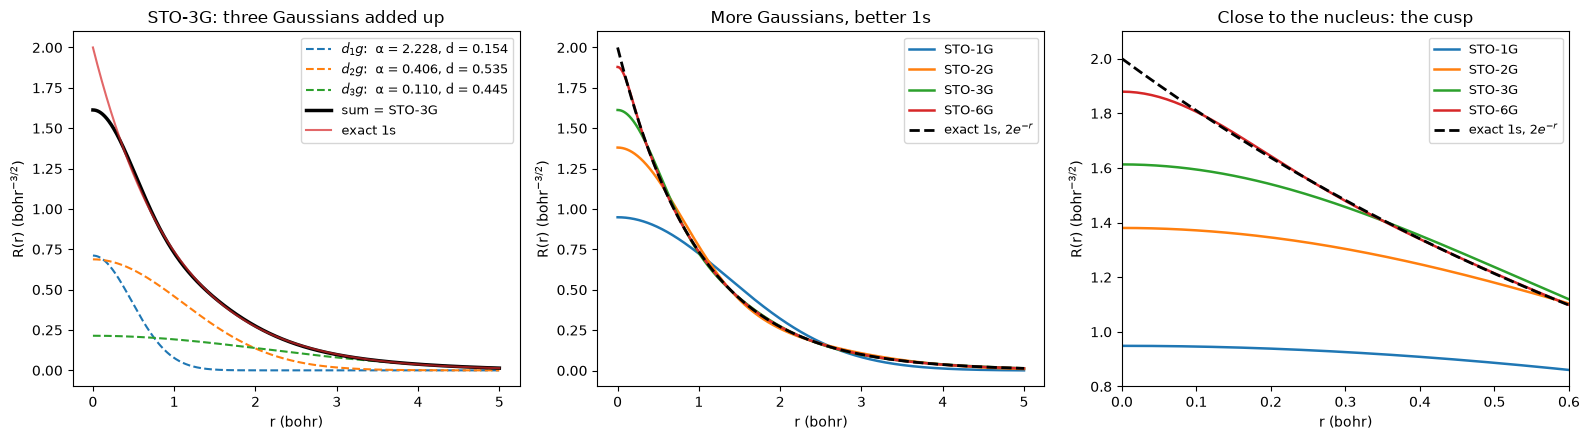

In [14]:
# Just run this cell: building the 1s orbital out of Gaussians
rr = np.linspace(0, 5, 1000)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

al, d = STO[3]
for i, (a, c) in enumerate(zip(al, d)):
    ax[0].plot(rr, c * gaussian_R(rr, a), '--', lw=1.5, label=f"$d_{i+1}g$:  α = {a:.3f}, d = {c:.3f}")
ax[0].plot(rr, sto_ng_R(rr, al, d), 'k-', lw=2.5, label='sum = STO-3G')
ax[0].plot(rr, R_1s(rr), color='C3', lw=1.5, alpha=0.7, label='exact 1s')
ax[0].set_title('STO-3G: three Gaussians added up')

for n, (al, d) in STO.items():
    ax[1].plot(rr, sto_ng_R(rr, al, d), lw=1.8, label=f"STO-{n}G")
    ax[2].plot(rr, sto_ng_R(rr, al, d), lw=1.8, label=f"STO-{n}G")
for a in ax[1:]:
    a.plot(rr, R_1s(rr), 'k--', lw=2, label='exact 1s, $2e^{-r}$')
ax[1].set_title('More Gaussians, better 1s')
ax[2].set_xlim(0, 0.6); ax[2].set_ylim(0.8, 2.1); ax[2].set_title('Close to the nucleus: the cusp')
for a in ax:
    a.set_xlabel('r (bohr)'); a.set_ylabel('R(r) (bohr$^{-3/2}$)'); a.legend(fontsize=9)
plt.tight_layout(); plt.show()

## 3. The Variational Principle

### 3.1 Statement
How do we know whether a wavefunction made of Gaussians is any good, when we can't compare it with the exact one? The answer is
the most useful theorem in quantum chemistry
([Atkins, Topic 9D.2](https://global.oup.com/academic/product/atkins-physical-chemistry-9780198769866);
[McQuarrie & Simon, Ch. 7](https://uscibooks.aip.org/books/physical-chemistry-a-molecular-approach/)):

<div style="border:2px solid #1f4e79; border-radius:8px; padding:10px 14px; background:#f3f7fb; color:#1a1a1a;">

**The variational principle.** For *any* trial wavefunction $\psi_\text{trial}$ (well-behaved, obeying the same boundary conditions),
the energy it predicts is **never below** the true ground-state energy $E_0$:

$$ E_\text{trial} = \frac{\int \psi_\text{trial}^*\,\hat H\,\psi_\text{trial}\,d\tau}{\int \psi_\text{trial}^*\,\psi_\text{trial}\,d\tau} \;\ge\; E_0 , $$

with equality only when $\psi_\text{trial}$ **is** the exact ground-state wavefunction.
</div>

**Why it is true.** Any trial function can be written as a combination of the exact eigenfunctions,
$\psi_\text{trial} = \sum_n c_n \psi_n$. Then $E_\text{trial} = \sum_n |c_n|^2 E_n \big/ \sum_n |c_n|^2$, an average of the exact
energies $E_0 \le E_1 \le E_2 \dots$, and an average can't be smaller than the smallest value it averages.

**How we use it.**
1. Give the trial function adjustable **parameters** (an exponent, a set of coefficients) and **minimize** the energy.
   The lowest energy is the best wavefunction of that form.
2. A lower energy means a better wavefunction, so we can compare two approximations **without knowing the exact answer**.
3. In a **linear** combination of basis functions, a larger basis set contains every combination the smaller one could make,
   plus more, so it can only lower the energy. Hylleraas and Undheim (1930) showed that each *excited-state* energy is also an
   upper bound to the true one and falls as the basis grows
   ([*Z. Phys.* **65**, 759](https://doi.org/10.1007/BF01397263)).

<div style="border-left:5px solid #7a5c00; background:#fff8e1; padding:10px 14px; color:#1a1a1a;">

**📜 Egil Hylleraas and the first accurate many-electron calculations.** In 1926 the Norwegian physicist
[Egil A. Hylleraas (1898–1965)](https://www.mn.uio.no/hylleraas/english/about/hylleraas/) went to Göttingen to work with
Max Born, who gave him a problem the new quantum mechanics had not yet passed: the helium atom. Hylleraas wrote trial
wavefunctions that depend on the distance **between the two electrons**, $r_{12}$, as well as on their distances from the nucleus,
and minimized the energy by hand calculation. His results ([1928](https://doi.org/10.1007/BF01340013),
[1929](https://doi.org/10.1007/BF01375457)) agreed with the measured ionization energy of helium, the first proof that
the Schrödinger equation works for more than one electron. With the same approach he predicted in 1930 that the hydride ion
H⁻ is stable (it was later detected in the Sun's atmosphere), and in 1931 he worked out a series solution for
the hydrogen molecule ion in elliptic coordinates ([*Z. Phys.* **71**, 739](https://doi.org/10.1007/BF01344443)),
the method later exact H₂⁺ calculations built on. James and Coolidge (1933) carried his $r_{12}$ idea to H₂, and
today's most accurate "explicitly correlated" methods still descend from it. Read his own account in
[*Rev. Mod. Phys.* **35**, 421 (1963)](https://doi.org/10.1103/RevModPhys.35.421).
</div>

### 3.2 One Gaussian for the hydrogen atom
Use the simplest possible trial function, **one** normalized Gaussian with an adjustable exponent $\alpha$. The kinetic and potential
energies have exact formulas (McQuarrie & Simon, Ch. 7), and their sum is the trial energy:

$$ E(\alpha) = \underbrace{\tfrac32\,\alpha}_{\text{kinetic}} \;\underbrace{-\;2\sqrt{\frac{2\alpha}{\pi}}}_{\text{potential}} \quad (E_h,\ \alpha\ \text{in bohr}^{-2}). $$

A tight Gaussian (large $\alpha$) keeps the electron close to the nucleus (low potential energy) but makes it move fast (high kinetic
energy). The variational principle picks the best compromise. For comparison, a Slater function $e^{-\zeta r}$ gives
$E(\zeta) = \tfrac12\zeta^2 - \zeta$, written for you.

### <font color=blue> **Question 3.1.** </font>
1. Complete `E_gauss(alpha)` with the formula above.
2. On the grid `alphas`, find the exponent with the lowest energy, `alpha_best`, and that energy, `E_gauss_best` (hartree).

<details><summary>💡 <b>Hint 1</b></summary>

`kinetic = 1.5 * alpha` and `potential = -2 * np.sqrt(2 * alpha / np.pi)`.
</details>
<details><summary>💡 <b>Hint 2</b></summary>

Same idea as `r_mp` in Question 2.1, with `np.argmin`: `alpha_best = alphas[np.argmin(E_alpha)]`, then `E_gauss_best = E_gauss(alpha_best)`.
</details>

best Gaussian:  alpha = 0.2822 bohr⁻²,  E = -0.42441 hartree
error above the exact -0.5 hartree: 2.057 eV


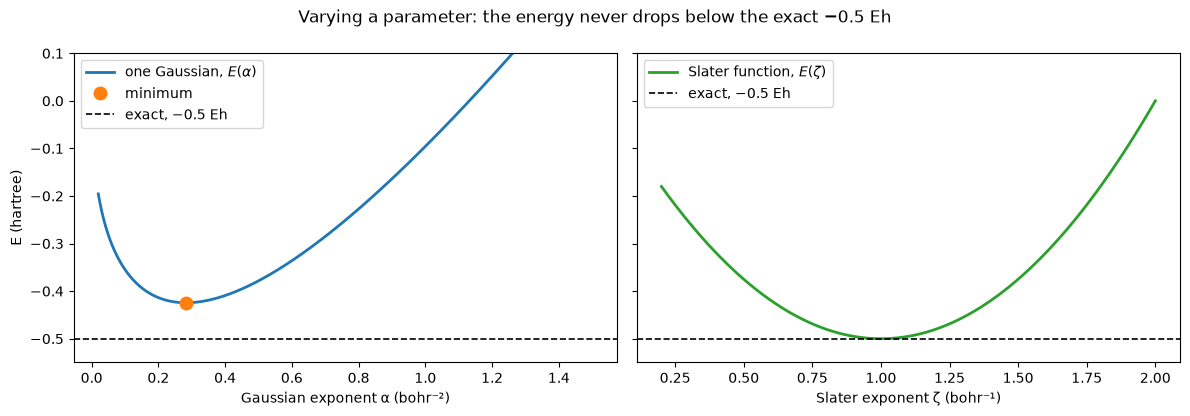

In [15]:
def E_gauss(alpha):
    """Variational energy (hartree) of the H atom with one normalized Gaussian of exponent alpha (bohr⁻²)."""
    kinetic = 1.5 * alpha
    potential = -2 * np.sqrt(2 * alpha / np.pi)
    return kinetic + potential

def E_slater(zeta):
    """Variational energy (hartree) of the H atom with a Slater 1s function exp(-zeta r)."""
    return 0.5 * zeta**2 - zeta

alphas = np.linspace(0.02, 1.5, 1000)    # bohr⁻²
E_alpha = E_gauss(alphas)
alpha_best = alphas[np.argmin(E_alpha)]
E_gauss_best = E_gauss(alpha_best)
print(f"best Gaussian:  alpha = {alpha_best:.4f} bohr⁻²,  E = {E_gauss_best:.5f} hartree")
print(f"error above the exact -0.5 hartree: {hartree_to_eV(E_gauss_best + 0.5):.3f} eV")

zetas = np.linspace(0.2, 2.0, 500)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
ax[0].plot(alphas, E_alpha, lw=2, label='one Gaussian, $E(\\alpha)$')
ax[0].plot(alpha_best, E_gauss_best, 'o', ms=9, color='C1', label='minimum')
ax[0].set_xlabel('Gaussian exponent α (bohr⁻²)')
ax[1].plot(zetas, E_slater(zetas), lw=2, color='C2', label='Slater function, $E(\\zeta)$')
ax[1].set_xlabel('Slater exponent ζ (bohr⁻¹)')
for a in ax:
    a.axhline(-0.5, color='k', ls='--', lw=1.2, label='exact, −0.5 Eh')
    a.set_ylim(-0.55, 0.1); a.legend()
ax[0].set_ylabel('E (hartree)')
fig.suptitle('Varying a parameter: the energy never drops below the exact −0.5 Eh')
plt.tight_layout(); plt.show()

In [16]:
lab.check('3.1')

### 3.3 Hylleraas's problem: the helium atom
Helium has two electrons, and the electron–electron repulsion $1/r_{12}$ means no exact formula exists. The simplest trial function
puts both electrons in a 1s-like orbital with an **effective nuclear charge** $\zeta$ in place of $Z = 2$:
$\psi = e^{-\zeta r_1}\,e^{-\zeta r_2}$. Working out the integrals gives (McQuarrie & Simon, Ch. 7; Atkins, Topic 8B)

$$ E(\zeta) = \zeta^2 - 2Z\zeta + \tfrac58\,\zeta = \zeta^2 - \tfrac{27}{8}\,\zeta \qquad (Z = 2). $$

The term $\tfrac58\zeta$ is the repulsion between the two electrons. For comparison:

| helium ground state | E ($E_h$) |
|---|---|
| exact (non-relativistic) | **−2.903724** |
| best possible single orbital (Hartree–Fock limit) | −2.861680 |

### <font color=blue> **Question 3.2.** </font>
Complete `E_He(zeta)`, then find `zeta_best` and `E_He_best` on the grid `zetas_He`, exactly as in Question 3.1.

<details><summary>💡 <b>Hint</b></summary>

`return zeta**2 - 27 / 8 * zeta`; `zeta_best = zetas_He[np.argmin(E_He(zetas_He))]`; `E_He_best = E_He(zeta_best)`.
</details>

In [17]:
def E_He(zeta):
    """Variational energy (hartree) of He with trial function exp(-zeta r1) exp(-zeta r2)."""
    return zeta**2 - 27 / 8 * zeta
zetas_He = np.linspace(1.0, 2.5, 1501)
zeta_best = zetas_He[np.argmin(E_He(zetas_He))]
E_He_best = E_He(zeta_best)
print(f"zeta_best = {zeta_best:.4f}   (the bare nucleus has Z = 2)")
print(f"E(He)     = {E_He_best:.5f} hartree")
print(f"above the exact -2.903724 hartree by {hartree_to_eV(E_He_best + 2.903724):.2f} eV")

zeta_best = 1.6880   (the bare nucleus has Z = 2)
E(He)     = -2.84766 hartree
above the exact -2.903724 hartree by 1.53 eV


In [18]:
lab.check('3.2')

### 3.4 More Gaussians: a lower energy
Now return to hydrogen with the STO-nG functions of Section 2.2. **Just run the cell below.** It gives PySCF your Gaussians as a
custom basis set, computes the energy for each, and plots it against the number of Gaussians.

STO-1G:  E = -0.424218 hartree   error =  2062.1 meV
STO-2G:  E = -0.481155 hartree   error =   512.8 meV
STO-3G:  E = -0.494907 hartree   error =   138.6 meV
STO-6G:  E = -0.499827 hartree   error =     4.7 meV
best single Gaussian (Question 3.1): E = -0.424412 hartree


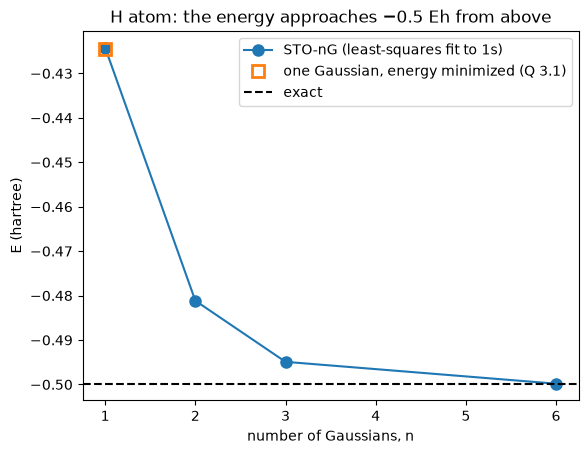

In [19]:
# Just run this cell: the H atom energy with the STO-nG fits (zeta = 1) of Section 2.2
E_sto = {}
for n, (al, d) in STO.items():
    basis = {'H': [[0] + [[a, c] for a, c in zip(al, d)]]}    # PySCF format: [l = 0 (s), [exponent, coefficient], ...]
    mol = gto.M(atom='H 0 0 0', basis=basis, spin=1, verbose=0)
    E_sto[n] = scf.UHF(mol).kernel()
    print(f"STO-{n}G:  E = {E_sto[n]:.6f} hartree   error = {1000 * hartree_to_eV(E_sto[n] + 0.5):7.1f} meV")
print(f"best single Gaussian (Question 3.1): E = {E_gauss_best:.6f} hartree")

plt.plot(list(E_sto), list(E_sto.values()), 'o-', ms=8, label='STO-nG (least-squares fit to 1s)')
plt.plot(1, E_gauss_best, 's', ms=9, mfc='none', mew=2, color='C1', label='one Gaussian, energy minimized (Q 3.1)')
plt.axhline(-0.5, color='k', ls='--', label='exact')
plt.xlabel('number of Gaussians, n'); plt.ylabel('E (hartree)'); plt.xticks([1, 2, 3, 4, 5, 6])
plt.title('H atom: the energy approaches −0.5 Eh from above'); plt.legend()
plt.show()

### 3.5 Standard basis sets in PySCF
Real calculations use basis sets from a library, chosen by name. Some common ones, from smallest to largest:

| basis set | functions on H | idea |
|---|---|---|
| `sto-3g` | 1 | one contracted 1s function (a "minimal" basis) |
| `6-31g` | 2 | two 1s functions, one tight and one loose |
| `cc-pvdz`, `cc-pvtz`, `cc-pvqz` | 5, 14, 30 | "correlation-consistent" double, triple, quadruple zeta: more s functions plus p, d, f functions |

One detail: PySCF's `sto-3g` for hydrogen is your STO-3G with every exponent multiplied by $1.24^2$, a **contracted** 1s
($\zeta = 1.24$) chosen because it works best for hydrogen **in molecules**. You will see why in Section 4.

For a **one-electron** system there is no electron–electron repulsion, so Hartree–Fock (HF) is the exact Schrödinger
equation. The **only** error is the basis set.

**Just run the cell below.** It is a complete calculation: build the atom, choose the method, solve.

In [20]:
# Just run this cell: a quantum chemistry calculation with a library basis set
mol = gto.M(atom='H 0 0 0',      # one H atom at the origin (x y z in Å)
            basis='sto-3g',      # the basis set
            spin=1,              # number of unpaired electrons (H has one)
            verbose=0)           # don't print PySCF's long log
mf = scf.UHF(mol)                # the method: (unrestricted) Hartree–Fock
E_sto3g = mf.kernel()            # solve; the energy is in hartree

print(f"E(H, STO-3G)  = {E_sto3g:.6f} hartree  = {E_sto3g * HARTREE_TO_EV:.3f} eV")
print(f"exact         = -0.500000 hartree  = {-0.5 * HARTREE_TO_EV:.3f} eV")
print(f"error         = {(E_sto3g + 0.5) * HARTREE_TO_EV:.3f} eV   (your zeta = 1 STO-3G: {(E_sto[3] + 0.5) * HARTREE_TO_EV:.3f} eV)")

E(H, STO-3G)  = -0.466582 hartree  = -12.696 eV
exact         = -0.500000 hartree  = -13.606 eV
error         = 0.909 eV   (your zeta = 1 STO-3G: 0.139 eV)


### <font color=blue> **Question 3.3.** </font>
Turn the worked example into a function, `h_atom_energy(basis)`, that returns the energy (hartree) of an H atom
for any basis set. The first line is done for you. Then run the cell: it loops over the basis sets and plots the error.

<details><summary>💡 <b>Hint 1</b></summary>

You need the two lines that come after `mol = ...` in the worked example: one that chooses the method, one that solves.
</details>
<details><summary>💡 <b>Hint 2</b></summary>

`mf = scf.UHF(mol)` and then `return mf.kernel()`.
</details>

sto-3g    E = -0.466582 hartree   error =   909.35 meV
6-31g     E = -0.498233 hartree   error =    48.08 meV
cc-pvdz   E = -0.499278 hartree   error =    19.64 meV
cc-pvtz   E = -0.499810 hartree   error =     5.18 meV
cc-pvqz   E = -0.499946 hartree   error =     1.48 meV


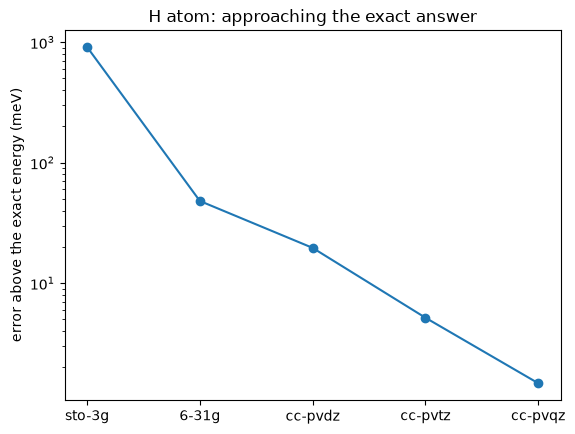

In [21]:
def h_atom_energy(basis):
    """Energy (hartree) of a hydrogen atom in the given basis set."""
    mol = gto.M(atom='H 0 0 0', basis=basis, spin=1, verbose=0)
    mf = scf.UHF(mol)
    return mf.kernel()
basis_sets = ['sto-3g', '6-31g', 'cc-pvdz', 'cc-pvtz', 'cc-pvqz']
E_H = {}                                   # a dictionary: basis set → energy
for b in basis_sets:
    E_H[b] = h_atom_energy(b)
    print(f"{b:8s}  E = {E_H[b]:.6f} hartree   error = {1000 * hartree_to_eV(E_H[b] + 0.5):8.2f} meV")

plt.semilogy(basis_sets, [1000 * hartree_to_eV(E_H[b] + 0.5) for b in basis_sets], 'o-')
plt.ylabel('error above the exact energy (meV)')
plt.title('H atom: approaching the exact answer')
plt.show()

In [22]:
lab.check('3.3')

### <font color=blue> **Question 3.4 Discussion.** </font>
<font color=green>

1. State the variational principle in your own words. Use it to explain why every energy in Sections 3.2–3.5 is above −0.5 hartree,
   and why adding Gaussians (or using a bigger basis set) can only lower the energy.
2. STO-1G was fitted to the *shape* of the 1s orbital; your best single Gaussian minimized the *energy*. Which has the lower energy,
   and why does the variational principle guarantee it? Is the best-energy Gaussian also the best-shaped one?
3. Look at the close-up of the nucleus. Why does a sum of Gaussians struggle to reproduce the exact orbital there, and why do
   chemists use Gaussians anyway?
4. For helium, why is `zeta_best` less than 2? Hylleraas got much closer to the exact energy by adding $r_{12}$ to the trial function:
   what physical behaviour of the two electrons does that let the wavefunction describe?
</font>

---

**Sample answer (instructor version).** 1. The energy of any trial wavefunction is greater than or equal to the true ground-state energy, with equality only for the exact wavefunction. Every calculation here used an approximate (Gaussian) wavefunction, so every energy is above −0.5 hartree. A larger set of functions can make every combination the smaller set could, plus more, so the lowest energy it finds is at least as low.
2. The energy-minimized Gaussian is lower (−0.42441 against −0.42422 hartree for STO-1G), as it must be: it is, by construction, the lowest energy any single Gaussian can give, and STO-1G is one particular single Gaussian. The two differ because a least-squares fit weights the shape everywhere, while the energy is most sensitive to the region near the nucleus. The best-energy function is not necessarily the best-shaped one.
3. e^{−r} has a cusp (non-zero slope) at the nucleus, but every Gaussian has zero slope there, so a finite sum of Gaussians is always flat at r = 0 and falls short of R(0) = 2 (STO-3G: 1.61). Tighter Gaussians improve this, but never reach a true cusp. Gaussians are used because the product of two Gaussians is a Gaussian, so all the multi-centre integrals have fast analytic formulas (Boys, 1950).
4. ζ = 27/16 = 1.69 < 2 because each electron partly shields the other from the nucleus: it sees an effective charge less than 2. A wavefunction that depends on r₁₂ can make the probability smaller when the two electrons are close together: the electrons avoid each other. This is electron correlation, which no single orbital product can describe.

---

#### Save notebook before check

In [23]:
lab.check('3.4d')

## 4. The Simplest Chemical Bond: H₂⁺

H₂⁺ has two protons and **one** electron, so, like the H atom, Hartree–Fock is exact and only the basis set limits the answer.
Its Schrödinger equation was first solved numerically by Burrau in 1927, the first quantum-mechanical treatment of a chemical bond;
Hylleraas's 1931 series solution in elliptic coordinates made accurate values easy to obtain. The exact Born–Oppenheimer results
([Bates, Ledsham & Stewart, *Phil. Trans. R. Soc. A* **246**, 215 (1953)](https://doi.org/10.1098/rsta.1953.0014)):

| | exact |
|---|---|
| bond length $R_e$ | 1.997 bohr = **1.057 Å** |
| energy at $R_e$ | **−0.602634** hartree |
| bond energy $D_e = E(\text{H}) + E(\text{H}^+) - E(R_e)$ | 0.102634 hartree = **2.793 eV** |

The products of breaking the bond are an H atom and a bare proton, H⁺, whose energy is zero (it has no electrons).

### 4.1 The LCAO trial function: bonding and antibonding orbitals
Near nucleus A the electron should look like a hydrogen 1s orbital on A, and near B like a 1s orbital on B. The simplest
trial function is therefore a **linear combination of atomic orbitals (LCAO)**: a two-function basis set, and the variational
principle gives two answers ([Atkins, Topic 9B](https://global.oup.com/academic/product/atkins-physical-chemistry-9780198769866);
McQuarrie & Simon, Ch. 9):

$$ \psi_\pm = \frac{\phi_A \pm \phi_B}{\sqrt{2(1 \pm S)}}, \qquad \phi_A = \frac{e^{-r_A}}{\sqrt\pi},\quad \phi_B = \frac{e^{-r_B}}{\sqrt\pi},
\qquad S(R) = \int \phi_A\phi_B\,d\tau = e^{-R}\left(1 + R + \frac{R^2}{3}\right). $$

$\psi_+$ is the **bonding** orbital, $\sigma_g$; $\psi_-$ is the **antibonding** orbital, $\sigma_u^*$. The **overlap integral** $S$
measures how much the two atomic orbitals share the same space, and the factor $\sqrt{2(1\pm S)}$ normalizes each one.
Along the bond axis (the $z$ axis, with A at $z = 0$ and B at $z = R$, everything in bohr), $r_A = |z|$ and $r_B = |z - R|$.

### <font color=blue> **Question 4.1.** </font>
1. Complete `overlap_S(R)` with the formula above (R in bohr).
2. Complete the `return` line of `psi_lcao(z, R, sign)`: the normalized combination $(\phi_A \pm \phi_B)/\sqrt{2(1 \pm S)}$, where
   `sign` is `+1` for $\sigma_g$ and `-1` for $\sigma_u^*$.

<details><summary>💡 <b>Hint 1</b></summary>

`return np.exp(-R) * (1 + R + R**2 / 3)`
</details>
<details><summary>💡 <b>Hint 2</b></summary>

`return (phi_A + sign * phi_B) / np.sqrt(2 * (1 + sign * overlap_S(R)))`
</details>

In [24]:
def overlap_S(R):
    """Overlap integral of two hydrogen 1s orbitals a distance R (bohr) apart."""
    return np.exp(-R) * (1 + R + R**2 / 3)
def psi_lcao(z, R, sign=+1):
    """LCAO orbital of H2+ along the bond axis (z and R in bohr): sign=+1 bonding σg, sign=-1 antibonding σu*."""
    phi_A = np.exp(-np.abs(z)) / np.sqrt(np.pi)          # 1s on nucleus A at z = 0
    phi_B = np.exp(-np.abs(z - R)) / np.sqrt(np.pi)      # 1s on nucleus B at z = R
    return (phi_A + sign * phi_B) / np.sqrt(2 * (1 + sign * overlap_S(R)))
print(f"S(R = 2 bohr) = {overlap_S(2.0):.4f}    S(R = 5 bohr) = {overlap_S(5.0):.4f}")
print(f"at the bond midpoint (R = 2 bohr):  σg = {psi_lcao(1.0, 2.0, +1):.4f},  σu* = {psi_lcao(1.0, 2.0, -1):.4f}")

S(R = 2 bohr) = 0.5865    S(R = 5 bohr) = 0.0966
at the bond midpoint (R = 2 bohr):  σg = 0.2330,  σu* = 0.0000


In [25]:
lab.check('4.1')

### 4.2 The wavefunctions along the bond, at two bond lengths
**Just run the cell below.** For two bond lengths, $R$ = 2.0 bohr (1.06 Å, the equilibrium bond) and $R$ = 5.0 bohr (2.65 Å, a
stretched bond), it plots along the bond axis:
- your **LCAO** orbitals (dashed), and
- the **accurate** orbitals (solid): the two lowest solutions of the one-electron Schrödinger equation in the large cc-pVTZ basis.
  For one electron this is just one matrix diagonalization, done with `eigh`.

The legend gives each orbital's total energy $E = \varepsilon + 1/R$. The energy of the LCAO orbitals has a formula too
([Atkins, Topic 9B.2](https://global.oup.com/academic/product/atkins-physical-chemistry-9780198769866)), written here as `lcao_energy`.

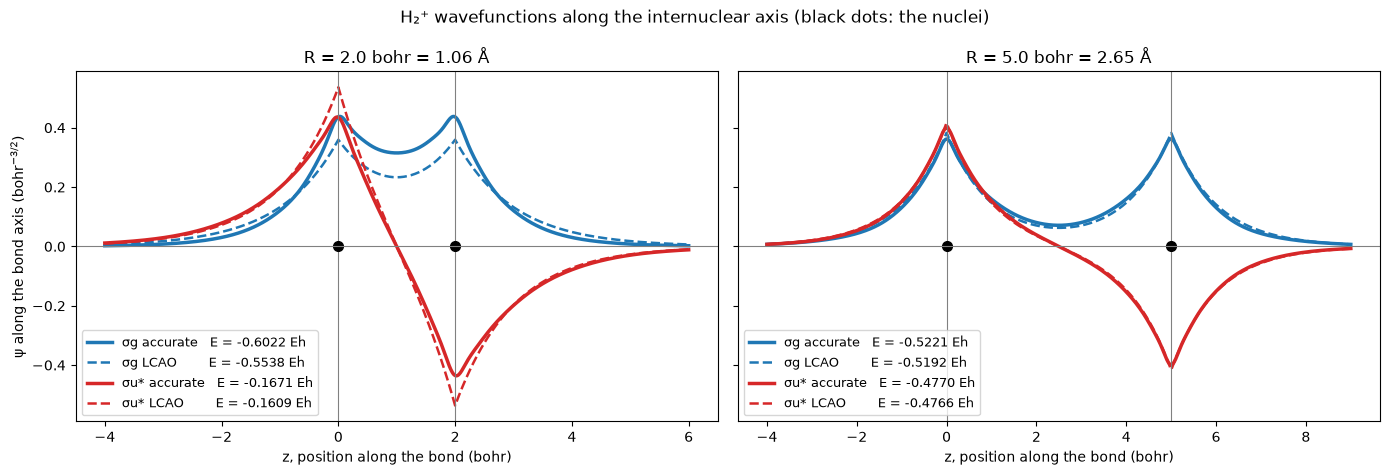

In [26]:
# Just run this cell: σg and σu* of H2+ along the bond axis, LCAO (dashed) and accurate (solid)
def lcao_energy(R, sign=+1):
    """LCAO total energy (hartree) of H2+ at R (bohr): E = E_1s + 1/R - (j ± k)/(1 ± S)."""
    j = 1 / R - np.exp(-2 * R) * (1 + 1 / R)        # Coulomb integral: density on A attracted by nucleus B
    k = np.exp(-R) * (1 + R)                         # resonance integral
    return -0.5 + 1 / R - (j + sign * k) / (1 + sign * overlap_S(R))

def h2plus_orbitals(R, z, basis='cc-pvtz'):
    """Two lowest exact-in-basis orbitals of H2+ (R, z in bohr): energies (hartree, incl. 1/R) and values along z."""
    mol = gto.M(atom=[['H', (0, 0, 0)], ['H', (0, 0, R)]], unit='Bohr', basis=basis, charge=1, spin=1, verbose=0)
    h = mol.intor('int1e_kin') + mol.intor('int1e_nuc')     # one-electron Hamiltonian matrix
    eps, C = eigh(h, mol.intor('int1e_ovlp'))               # solve H c = ε S c
    pts = np.zeros((len(z), 3)); pts[:, 2] = z
    psi = mol.eval_gto('GTOval', pts) @ C[:, :2]
    psi = psi * np.sign(psi[np.argmin(np.abs(z))])           # sign convention: positive on nucleus A
    return eps[:2] + 1 / R, psi

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for a, R_b in zip(ax, (2.0, 5.0)):
    z = np.linspace(-4, R_b + 4, 801)
    E_acc, psi = h2plus_orbitals(R_b, z)
    for i, (sign, orbital, col) in enumerate(((+1, 'σg', 'C0'), (-1, 'σu*', 'C3'))):
        a.plot(z, psi[:, i], '-', color=col, lw=2.5, label=f"{orbital} accurate   E = {E_acc[i]:.4f} Eh")
        a.plot(z, psi_lcao(z, R_b, sign), '--', color=col, lw=1.8,
               label=f"{orbital} LCAO        E = {lcao_energy(R_b, sign):.4f} Eh")
    for zn in (0, R_b):
        a.axvline(zn, color='gray', lw=0.8); a.plot(zn, 0, 'ko', ms=7)
    a.axhline(0, color='gray', lw=0.8)
    a.set_title(f"R = {R_b:.1f} bohr = {bohr_to_angstrom(R_b):.2f} Å")
    a.set_xlabel('z, position along the bond (bohr)'); a.legend(fontsize=9, loc='lower left')
ax[0].set_ylabel('ψ along the bond axis (bohr$^{-3/2}$)')
fig.suptitle('H₂⁺ wavefunctions along the internuclear axis (black dots: the nuclei)')
plt.tight_layout(); plt.show()

### <font color=blue> **Question 4.2.** </font>
Complete `h2plus_energy(R)`: set the `charge` and `spin` for H₂⁺, and return the energy, as in Question 3.3.
The two H atoms are at $(0, 0, 0)$ and $(0, 0, R)$, with $R$ in Å.

<details><summary>💡 <b>Hint 1</b></summary>

Two protons (+2) and one electron (−1): what is the total charge? How many electrons are unpaired?
</details>
<details><summary>💡 <b>Hint 2</b></summary>

`charge = 1`, `spin = 1`, and `return mf.kernel()`.
</details>

In [27]:
def h2plus_energy(R, basis='cc-pvtz'):
    """Total energy (hartree) of H2+ with bond length R (Å)."""
    charge = 1
    spin = 1
    mol = gto.M(atom=[['H', (0, 0, 0)], ['H', (0, 0, R)]], basis=basis,
                charge=charge, spin=spin, verbose=0)
    mf = scf.UHF(mol)
    return mf.kernel()
print(f"E(H2+, R = 1.057 Å) = {h2plus_energy(1.057):.6f} hartree   (exact at R_e: -0.602634)")

E(H2+, R = 1.057 Å) = -0.602245 hartree   (exact at R_e: -0.602634)


In [28]:
lab.check('4.2')

### <font color=blue> **Question 4.3.** </font>
Compute the potential energy curve: the energy at every bond length in `R_grid`. Store the results in the array `E_h2p`.
The plot compares your curve with the minimal LCAO curve, the variational energy of $\psi_+$.

🐍 **Python tip — list comprehensions.** `[f(R) for R in R_grid]` calls `f` once for each value in `R_grid` and collects the
results in a list. `np.array(...)` turns the list into an array, so you can do math on all the values at once.

<details><summary>💡 <b>Hint</b></summary>

`E_h2p = np.array([h2plus_energy(R) for R in R_grid])`
</details>

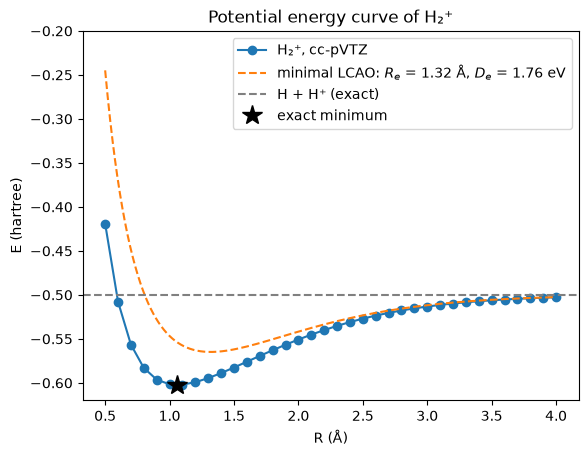

In [29]:
R_grid = np.linspace(0.5, 4.0, 36)         # bond lengths, Å
E_h2p = np.array([h2plus_energy(R) for R in R_grid])
R_fine = np.linspace(0.5, 4.0, 3501)       # Å, for the LCAO formula
E_lcao = lcao_energy(R_fine / BOHR_TO_ANG)
R_e_lcao, De_lcao = R_fine[np.argmin(E_lcao)], hartree_to_eV(-0.5 - E_lcao.min())

plt.plot(R_grid, E_h2p, 'o-', label='H₂⁺, cc-pVTZ')
plt.plot(R_fine, E_lcao, '--', color='C1', label=f'minimal LCAO: $R_e$ = {R_e_lcao:.2f} Å, $D_e$ = {De_lcao:.2f} eV')
plt.axhline(-0.5, color='gray', ls='--', label='H + H⁺ (exact)')
plt.plot(1.057, -0.602634, '*', ms=15, color='k', label='exact minimum')
plt.xlabel('R (Å)'); plt.ylabel('E (hartree)'); plt.ylim(-0.62, -0.2)
plt.title('Potential energy curve of H₂⁺'); plt.legend()
plt.show()

In [30]:
lab.check('4.3')

### 4.4 Bond length, bond energy and force constant
Near its minimum every smooth curve looks like a parabola,

$$ E(R) \approx E_\text{min} + \tfrac12\,k\,(R - R_e)^2 , $$

where $k$, the curvature, is the bond's **force constant**: a stiff bond has a large $k$.
The helper below finds $R_e$, $E_\text{min}$ and $k$ by fitting a polynomial to a few closely spaced points near the minimum.

🐍 **Python tip — passing a function to a function.** `harmonic_fit(h2plus_energy, 1.06)` hands your *function* (no parentheses!)
to the helper, which calls it as many times as it needs.

In [31]:
# Just run this cell: fits a polynomial near the minimum of any energy function
def harmonic_fit(energy_function, R_guess, **options):
    """Return R_e (Å), E_min (hartree) and k = E''(R_e) (hartree/Å²) for energy_function(R, **options)."""
    center = R_guess
    for _ in range(2):                                     # fit twice, re-centring on the minimum
        R = center + np.linspace(-0.06, 0.06, 7)           # 7 points within ±0.06 Å
        E = np.array([energy_function(r, **options) for r in R])
        p = np.polyfit(R - center, E, 4)                   # quartic in (R - center)
        roots = np.roots(np.polyder(p))                    # where the slope is zero
        x = roots[np.argmin(np.abs(roots))].real           # the stationary point nearest the centre
        R_e, E_min, k = center + x, np.polyval(p, x), np.polyval(np.polyder(p, 2), x)
        center = R_e
    return R_e, E_min, k

R_e_h2p, E_min_h2p, k_h2p = harmonic_fit(h2plus_energy, 1.06)
print(f"H2+: R_e = {R_e_h2p:.4f} Å,  E_min = {E_min_h2p:.6f} hartree,  k = {k_h2p:.4f} hartree/Å²")

H2+: R_e = 1.0572 Å,  E_min = -0.602245 hartree,  k = 0.3711 hartree/Å²


### <font color=blue> **Question 4.4.** </font>
Compute the bond energy of H₂⁺ in eV, `De_h2p`. Use the H atom energy **in the same basis set** (`E_H['cc-pvtz']`), so
that the basis-set errors partly cancel. Compare with the exact 2.793 eV.

<details><summary>💡 <b>Hint</b></summary>

$D_e = E(\text{H}) + E(\text{H}^+) - E_\text{min}$ with $E(\text{H}^+) = 0$, converted to eV:
`De_h2p = hartree_to_eV(E_H['cc-pvtz'] - E_min_h2p)`
</details>

In [32]:
De_h2p = hartree_to_eV(E_H['cc-pvtz'] - E_min_h2p)
print(f"D_e(H2+) = {De_h2p:.3f} eV   (exact 2.793 eV;  minimal LCAO {De_lcao:.2f} eV)")
print(f"R_e(H2+) = {R_e_h2p:.4f} Å  (exact 1.057 Å;  minimal LCAO {R_e_lcao:.2f} Å)")

D_e(H2+) = 2.787 eV   (exact 2.793 eV;  minimal LCAO 1.76 eV)
R_e(H2+) = 1.0572 Å  (exact 1.057 Å;  minimal LCAO 1.32 Å)


In [33]:
lab.check('4.4')

### 4.5 Where does the bond come from?
**Just run the cell below.** The left plot splits the energy into the electronic energy and the nuclear repulsion
$V_{nn} = 1/R$ (atomic units). The right plot shows the electron density along the bond axis at $R_e$, compared with what it
would be if the electron were simply shared half-and-half between two undisturbed H atoms.

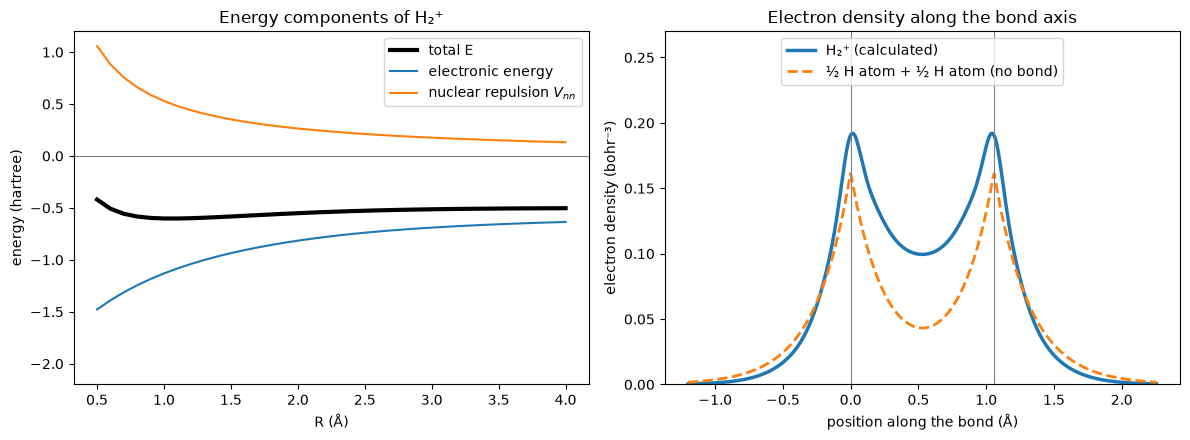

In [34]:
# Just run this cell: energy components and the electron density of the bond
V_nn = 1 / (R_grid / BOHR_TO_ANG)                       # hartree; 1/R with R in bohr
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(R_grid, E_h2p, 'k-', lw=3, label='total E')
ax[0].plot(R_grid, E_h2p - V_nn, label='electronic energy')
ax[0].plot(R_grid, V_nn, label='nuclear repulsion $V_{nn}$')
ax[0].axhline(0, color='gray', lw=0.8)
ax[0].set_xlabel('R (Å)'); ax[0].set_ylabel('energy (hartree)'); ax[0].set_ylim(-2.2, 1.2); ax[0].legend()
ax[0].set_title('Energy components of H₂⁺')

mol = gto.M(atom=[['H', (0, 0, 0)], ['H', (0, 0, R_e_h2p)]], basis='cc-pvtz', charge=1, spin=1, verbose=0)
mf = scf.UHF(mol); mf.kernel()
dm = mf.make_rdm1()[0] + mf.make_rdm1()[1]
z = np.linspace(-1.2, R_e_h2p + 1.2, 500)                 # Å, along the bond axis
pts = np.zeros((len(z), 3)); pts[:, 2] = z / BOHR_TO_ANG  # PySCF wants bohr here
ao = mol.eval_gto('GTOval', pts)
rho_bond = np.einsum('pi,ij,pj->p', ao, dm, ao)
r1, r2 = np.abs(z) / BOHR_TO_ANG, np.abs(z - R_e_h2p) / BOHR_TO_ANG
rho_atoms = 0.5 * (np.exp(-2 * r1) + np.exp(-2 * r2)) / np.pi   # exact 1s densities, half an electron on each
ax[1].plot(z, rho_bond, lw=2.5, label='H₂⁺ (calculated)')
ax[1].plot(z, rho_atoms, '--', lw=2, label='½ H atom + ½ H atom (no bond)')
ax[1].axvline(0, color='gray', lw=0.8); ax[1].axvline(R_e_h2p, color='gray', lw=0.8)
ax[1].set_xlabel('position along the bond (Å)'); ax[1].set_ylabel('electron density (bohr⁻³)')
ax[1].set_ylim(0, 0.27); ax[1].set_title('Electron density along the bond axis'); ax[1].legend(loc='upper center')
plt.tight_layout(); plt.show()

### <font color=blue> **Question 4.5 Discussion.** </font>
<font color=green>

1. **Wavefunctions (Section 4.2).** Where does $\sigma_u^*$ have a node, and why must it? Compare the two bond lengths: how do the
   energy gap between $\sigma_g$ and $\sigma_u^*$ and the agreement between LCAO and accurate orbitals change as the bond is stretched?
   What energy do both orbitals approach as $R \to \infty$?
2. At $R$ = 2 bohr the accurate $\sigma_g$ is taller at the nuclei than the LCAO one. What does that say about the best exponent $\zeta$
   for hydrogen in a molecule? Connect this to the $\zeta = 1.24$ in PySCF's `sto-3g` (Section 3.5).
3. In the density plot, where has the electron gone when the bond forms, compared with two separate half-atoms? Why does
   putting electron density **between** the nuclei lower the energy?
4. In the energy plot, the electronic energy keeps falling as $R$ shrinks, but the total energy has a minimum. What sets
   the bond length?
5. How close are your $R_e$ and $D_e$ to the exact values, and to the minimal LCAO? Explain the ordering
   exact < cc-pVTZ < LCAO using the variational principle.
</font>

---

**Sample answer (instructor version).** 1. σu* = (φA − φB)/… changes sign at the midpoint z = R/2 because it is odd (ungerade) under inversion through the centre, so it must vanish there. At 2 bohr the gap is large (σg −0.602, σu* −0.167 Eh) and the LCAO noticeably underestimates the bonding orbital near the nuclei; at 5 bohr the gap is small (−0.522 against −0.477 Eh) and the LCAO and accurate orbitals almost coincide, because each half now looks like an undisturbed H 1s. As R → ∞ both energies approach −0.5 Eh, the energy of H + H⁺, and the two orbitals become degenerate.
2. The accurate orbital is contracted towards the nuclei: the best exponent is larger than 1. Letting ζ vary in the LCAO gives ζ ≈ 1.24 at R = 2 bohr (D_e rises from 1.76 to 2.35 eV), the same contraction built into PySCF's STO-3G hydrogen, which is optimized for molecules, not for the free atom.
3. The density piles up between the nuclei (and is depleted just outside them) compared with two undisturbed half-atoms. Density between the nuclei is attracted by both protons at once, which lowers the potential energy; the electron is also spread over a larger region, which lowers its kinetic energy (the original explanation; modern analyses add the orbital contraction near each nucleus seen in question 2).
4. The electronic energy falls steadily as the nuclei approach (the electron is attracted by two nuclei that are close together), but the nuclear repulsion 1/R rises steeply at short R. The bond length is where the two balance: the minimum of their sum.
5. Reference run: cc-pVTZ R_e = 1.057 Å and D_e ≈ 2.79 eV (exact 1.057 Å, 2.793 eV); minimal LCAO 1.32 Å and 1.76 eV. Both are variational calculations, so both energies lie above the exact curve; the cc-pVTZ basis contains far more functions (and can describe the contraction and polarization of the orbital), so its energy is much lower and closer to exact. The only approximation in the cc-pVTZ result is the finite basis set (plus the Born–Oppenheimer approximation, which defines the problem).

---

#### Save notebook before check

In [35]:
lab.check('4.5d')

## 5. Two Electrons: H₂ and Electron Correlation

### 5.1 Hartree–Fock is now an approximation
With two electrons, each electron repels the other. **Hartree–Fock** replaces that instantaneous repulsion by the *average*
field of the other electron: each electron sees a smeared-out cloud, not a particle it can dodge. This is the same
single-orbital picture as the $e^{-\zeta r_1}e^{-\zeta r_2}$ trial function for helium in Section 3.3, and it misses the same thing.
The energy it misses is the **correlation energy**:

$$ E_\text{corr} = E_\text{exact} - E_\text{HF} \quad (< 0). $$

**Full configuration interaction (FCI)** writes the wavefunction as a combination of *every* possible arrangement
(determinant) of the electrons in the orbitals. Within a given basis set it is the **exact** answer. Its cost explodes with the
number of electrons, but for two electrons it takes a fraction of a second.

The exact values below come from Hylleraas's idea of putting $r_{12}$ directly into the wavefunction: James and Coolidge
([*J. Chem. Phys.* **1**, 825 (1933)](https://doi.org/10.1063/1.1749252)) used it for H₂, and Kołos and Wolniewicz
([*J. Chem. Phys.* **49**, 404 (1968)](https://doi.org/10.1063/1.1669836)) pushed it to spectroscopic accuracy
(see also [Pachucki, *Phys. Rev. A* **82**, 032509 (2010)](https://doi.org/10.1103/PhysRevA.82.032509)). Experiment:
[Huber & Herzberg, *Constants of Diatomic Molecules* (1979)](https://webbook.nist.gov/cgi/cbook.cgi?ID=C1333740&Mask=1000).

| | exact / experiment |
|---|---|
| $R_e$ | **0.7414 Å** |
| $E$ at $R_e$ | **−1.174476** hartree |
| $D_e = 2E(\text{H}) - E(R_e)$ | 0.174476 hartree = **4.748 eV** |
| harmonic wavenumber $\tilde\nu_e$ | **4401** cm⁻¹ |

### <font color=blue> **Question 5.1.** </font>
Complete `h2_energy(R, method)`. The Hartree–Fock part is written for you. For `method='fci'`, run full CI on top of the
Hartree–Fock result with PySCF's `fci.FCI(mf).kernel()`. It returns **two** things, the energy and the wavefunction; keep the energy.

<details><summary>💡 <b>Hint 1</b></summary>

When a function returns two things, `[0]` picks the first: `fci.FCI(mf).kernel()[0]`.
</details>
<details><summary>💡 <b>Hint 2</b></summary>

`E_fci = fci.FCI(mf).kernel()[0]`
</details>

In [36]:
def h2_energy(R, method='fci', basis='cc-pvtz'):
    """Total energy (hartree) of H2 with bond length R (Å); method is 'hf' or 'fci'."""
    mol = gto.M(atom=[['H', (0, 0, 0)], ['H', (0, 0, R)]], basis=basis, verbose=0)
    mf = scf.RHF(mol)            # restricted HF: both electrons in the same spatial orbital
    E_hf = mf.kernel()
    if method == 'hf':
        return E_hf
    E_fci = fci.FCI(mf).kernel()[0]
    return E_fci

print(f"HF:  E(R = 0.7414 Å) = {h2_energy(0.7414, 'hf'):.6f} hartree")
print(f"FCI: E(R = 0.7414 Å) = {h2_energy(0.7414, 'fci'):.6f} hartree   (exact -1.174476)")

HF:  E(R = 0.7414 Å) = -1.132955 hartree


FCI: E(R = 0.7414 Å) = -1.172336 hartree   (exact -1.174476)


In [37]:
lab.check('5.1')

### <font color=blue> **Question 5.2.** </font>
Compute HF and FCI curves on `R_grid2`, as you did for H₂⁺, and store them in `E_hf_curve` and `E_fci_curve`. Then compute the
correlation energy at every point, `E_corr` (hartree).

<details><summary>💡 <b>Hint</b></summary>

`E_hf_curve = np.array([h2_energy(R, 'hf') for R in R_grid2])`; the FCI curve is the same with `'fci'`.
`E_corr` is just a subtraction of two arrays.
</details>

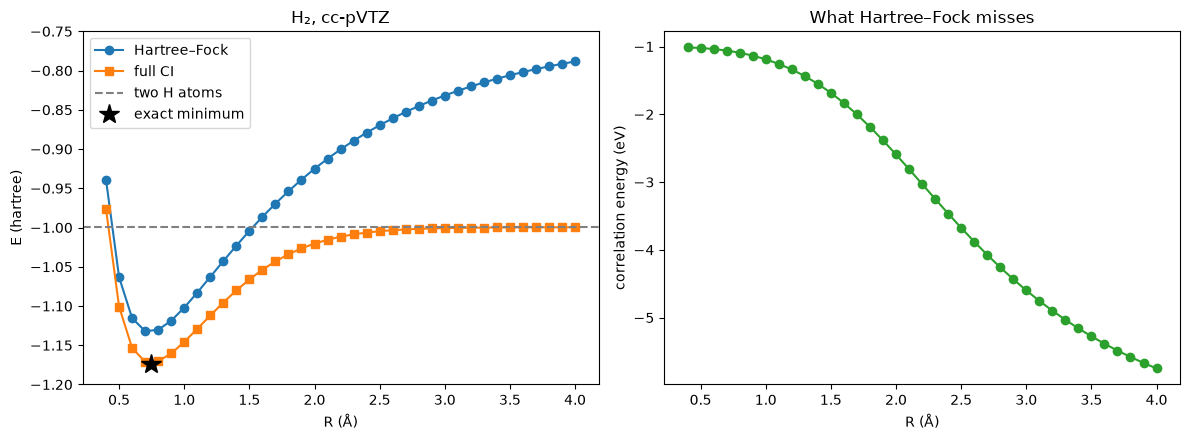

In [38]:
R_grid2 = np.linspace(0.4, 4.0, 37)        # Å
E_hf_curve = np.array([h2_energy(R, 'hf') for R in R_grid2])
E_fci_curve = np.array([h2_energy(R, 'fci') for R in R_grid2])
E_corr = E_fci_curve - E_hf_curve
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(R_grid2, E_hf_curve, 'o-', label='Hartree–Fock')
ax[0].plot(R_grid2, E_fci_curve, 's-', label='full CI')
ax[0].axhline(2 * E_H['cc-pvtz'], color='gray', ls='--', label='two H atoms')
ax[0].plot(0.7414, -1.174476, '*', ms=15, color='k', label='exact minimum')
ax[0].set_xlabel('R (Å)'); ax[0].set_ylabel('E (hartree)'); ax[0].set_ylim(-1.2, -0.75); ax[0].legend()
ax[0].set_title('H₂, cc-pVTZ')
ax[1].plot(R_grid2, hartree_to_eV(E_corr), 'o-', color='C2')
ax[1].set_xlabel('R (Å)'); ax[1].set_ylabel('correlation energy (eV)')
ax[1].set_title('What Hartree–Fock misses')
plt.tight_layout(); plt.show()

In [39]:
lab.check('5.2')

### <font color=blue> **Question 5.3.** </font>
The vibrational wavenumber of a diatomic comes from the force constant and the **reduced mass** $\mu = m_1 m_2/(m_1+m_2)$:

$$ \omega = \sqrt{k/\mu}, \qquad \tilde\nu_e = \frac{\omega}{2\pi c}. $$

Complete `harmonic_wavenumber(k, m1, m2)` for $k$ in hartree/Å² and masses in amu. Work in SI units:
1. convert $k$ to N m⁻¹ (J m⁻²): multiply by `HARTREE_TO_J` and divide by $(10^{-10})^2 = 10^{-20}$ m² per Å²;
2. $\mu$ in kg (`AMU_TO_KG`); 3. $\omega$ in s⁻¹; 4. $\tilde\nu_e$ in cm⁻¹ with $c$ in cm s⁻¹ (`C_CM_PER_S`).

Check: H³⁵Cl has $k$ = 516 N m⁻¹ and $\tilde\nu_e$ = 2991 cm⁻¹.

<details><summary>💡 <b>Hint</b></summary>

```
k_SI = k * HARTREE_TO_J / 1e-20
mu = m1 * m2 / (m1 + m2) * AMU_TO_KG
omega = np.sqrt(k_SI / mu)
return omega / (2 * np.pi * C_CM_PER_S)
```
</details>

In [40]:
def harmonic_wavenumber(k, m1, m2):
    """Harmonic wavenumber (cm⁻¹) from force constant k (hartree/Å²) and atomic masses m1, m2 (amu)."""
    k_SI = k * HARTREE_TO_J / 1e-20    # N/m
    mu = m1 * m2 / (m1 + m2) * AMU_TO_KG    # kg
    omega = np.sqrt(k_SI / mu)    # s⁻¹
    return omega / (2 * np.pi * C_CM_PER_S)
print(f"HCl check: {harmonic_wavenumber(1.18424, 1.007825, 34.968853):.0f} cm⁻¹  (expected 2991)")

HCl check: 2991 cm⁻¹  (expected 2991)


In [41]:
lab.check('5.3')

### <font color=blue> **Question 5.4.** </font>
The fits for both methods are done for you. Compute the bond energies `De_hf` and `De_fci` (eV) relative to **two H atoms** in
the same basis, and the harmonic wavenumbers `nu_hf` and `nu_fci` (cm⁻¹).

<details><summary>💡 <b>Hint</b></summary>

`De_fci = hartree_to_eV(2 * E_H['cc-pvtz'] - E_min_fci)` and `nu_fci = harmonic_wavenumber(k_fci, M_H, M_H)`; the HF lines are the same with `hf`.
</details>

In [42]:
R_e_hf, E_min_hf, k_hf = harmonic_fit(h2_energy, 0.74, method='hf')
R_e_fci, E_min_fci, k_fci = harmonic_fit(h2_energy, 0.74, method='fci')

De_hf = hartree_to_eV(2 * E_H['cc-pvtz'] - E_min_hf)
De_fci = hartree_to_eV(2 * E_H['cc-pvtz'] - E_min_fci)
nu_hf = harmonic_wavenumber(k_hf, M_H, M_H)
nu_fci = harmonic_wavenumber(k_fci, M_H, M_H)
print(f"{'':10s} {'R_e (Å)':>8s} {'D_e (eV)':>9s} {'ν̃e (cm⁻¹)':>11s}")
print(f"{'HF':10s} {R_e_hf:8.4f} {De_hf:9.3f} {nu_hf:11.0f}")
print(f"{'full CI':10s} {R_e_fci:8.4f} {De_fci:9.3f} {nu_fci:11.0f}")
print(f"{'exact':10s} {0.7414:8.4f} {4.748:9.3f} {4401:11.0f}")

            R_e (Å)  D_e (eV)  ν̃e (cm⁻¹)
HF           0.7344     3.629        4587
full CI      0.7426     4.700        4409
exact        0.7414     4.748        4401


In [43]:
lab.check('5.4')

### <font color=blue> **Question 5.5 Discussion.** </font>
<font color=green>

1. The Hartree–Fock curve does not go to the energy of two H atoms when the bond is broken. Restricted HF puts both electrons in
   the same bonding orbital $\sigma_g = (1s_A + 1s_B)/\sqrt2$. Multiply out $\sigma_g(1)\,\sigma_g(2)$: what fraction of the
   wavefunction describes H⁺ + H⁻? Why is that wrong at large $R$?
2. Why does the correlation energy grow as the bond stretches?
3. Which property does correlation change most: $R_e$, $D_e$ or $\tilde\nu_e$? Why does a method that misses correlation
   give a bond that is too stiff and too weak?
</font>

---

**Sample answer (instructor version).** 1. σg(1)σg(2) = ½[1sA(1)1sB(2) + 1sB(1)1sA(2)] + ½[1sA(1)1sA(2) + 1sB(1)1sB(2)]: half covalent (H·H) and half ionic (H⁺H⁻, both electrons on one atom). At large R the true state is two neutral H atoms; the ionic half costs about IE − EA ≈ 12.8 eV, so HF goes far too high.
2. At R_e the electrons share a compact orbital and the mean-field picture is reasonable. As R grows, the electrons should be on different atoms (left-right correlation), which a single doubly occupied orbital cannot describe, so the error (the correlation energy) grows until it equals the ionic penalty that FCI removes.
3. D_e changes most (reference run: HF ≈ 3.6 eV against 4.7 eV for FCI). HF is also too stiff (ν̃e ≈ 4580 against ≈ 4400 cm⁻¹) and slightly too short. Correlation mixes in a little antibonding (σu²) character, which lengthens and softens the bond; without it, the bonding orbital is overpopulated, so the bond is too stiff. The well is too shallow because the HF energy is too high everywhere, and most of all where the electrons should be correlated.

---

#### Save notebook before check

In [44]:
lab.check('5.5d')

## 6. Sixteen Electrons: O₂ with Density Functional Theory

### 6.1 Why we can't do full CI for O₂
The number of determinants in full CI is the number of ways to place the α electrons in the orbitals, times the number of
ways to place the β electrons:

$$ N_\text{det} = \binom{n_\text{orb}}{n_\alpha}\binom{n_\text{orb}}{n_\beta} $$

H₂ in cc-pVTZ and O₂ in the small cc-pVDZ basis both have **28 orbitals**. H₂ has 1 α and 1 β electron;
O₂ (a triplet) has 9 α and 7 β.

🐍 **Python tip:** `math.comb(n, k)` counts the ways to choose `k` things from `n`: `math.comb(28, 1)` is 28.

### <font color=blue> **Question 6.1.** </font>
Compute `n_det_H2` and `n_det_O2`. The cell then estimates the memory needed just to *store* one number per determinant.

<details><summary>💡 <b>Hint</b></summary>

`n_det_O2 = math.comb(28, 9) * math.comb(28, 7)`
</details>

In [45]:
n_det_H2 = math.comb(28, 1) * math.comb(28, 1)
n_det_O2 = math.comb(28, 9) * math.comb(28, 7)
print(f"H2: {n_det_H2:,} determinants")
print(f"O2: {n_det_O2:,} determinants  →  {n_det_O2 * 8 / 1e12:.0f} TB just to store the wavefunction")

H2: 784 determinants
O2: 8,178,045,876,000 determinants  →  65 TB just to store the wavefunction


In [46]:
lab.check('6.1')

### 6.2 Density functional theory
**Density functional theory (DFT)** avoids the wavefunction altogether. Hohenberg and Kohn proved that the ground-state energy is
determined by the electron **density** $\rho(\mathbf r)$, a function of just three coordinates however many electrons there are.
The catch: the exact functional is unknown, so we use an approximate **exchange–correlation functional**. Here we use
**B3LYP**, the most widely used one, with the **def2-SVP** basis set. A DFT calculation on O₂ takes about a second.
One consequence: an approximate functional is **not variational** in the sense of Section 3, so a DFT energy is not guaranteed to lie
above the exact energy.

O₂ has 16 electrons. Its two highest electrons go into a pair of degenerate π* orbitals, so it can be a **triplet**
(one electron in each, spins parallel, `spin=2`) or a **closed-shell singlet** (both in one, paired, `spin=0`).
Unrestricted DFT (`dft.UKS`) lets the α and β electrons have different orbitals, which an open-shell molecule needs.
Restricted DFT (`dft.RKS`) pairs them, as for a closed shell.

### <font color=blue> **Question 6.2.** </font>
Complete `o2_energy(R, spin)`: choose `dft.UKS(mol)` when `spin > 0` and `dft.RKS(mol)` otherwise, and return the energy (hartree).

🐍 **Python tip — choosing in one line.** `a if condition else b` gives `a` when the condition is true, otherwise `b`.

<details><summary>💡 <b>Hint</b></summary>

`mf = dft.UKS(mol) if spin > 0 else dft.RKS(mol)` and `return mf.kernel()`.
</details>

In [47]:
def o2_energy(R, spin=2, xc='b3lyp', basis='def2-svp'):
    """B3LYP total energy (hartree) of O2 with bond length R (Å) and `spin` unpaired electrons."""
    mol = gto.M(atom=[['O', (0, 0, 0)], ['O', (0, 0, R)]], basis=basis, spin=spin, verbose=0)
    mf = dft.UKS(mol) if spin > 0 else dft.RKS(mol)
    mf.xc = xc
    return mf.kernel()
print(f"E(O2, triplet, R = 1.21 Å) = {o2_energy(1.21, spin=2):.6f} hartree")

E(O2, triplet, R = 1.21 Å) = -150.204643 hartree


In [48]:
lab.check('6.2')

### <font color=blue> **Question 6.3.** </font>
Compute the triplet and singlet curves on `R_grid3` (`E_trip` and `E_sing`, hartree), as for H₂ (about 30 s).

<details><summary>💡 <b>Hint</b></summary>

`E_trip = np.array([o2_energy(R, spin=2) for R in R_grid3])`, and the same with `spin=0` for the singlet.
</details>

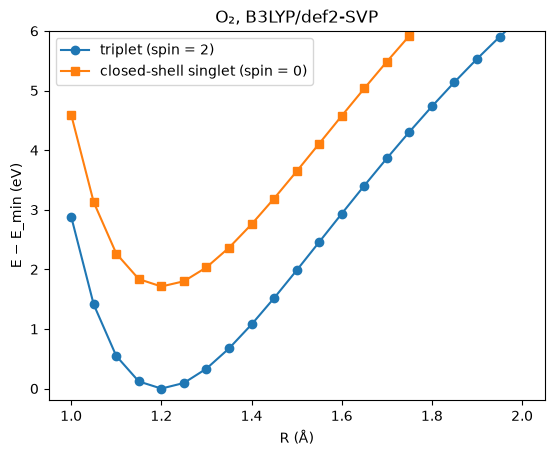

singlet − triplet at R = 1.20 Å: 1.71 eV


In [49]:
R_grid3 = np.linspace(1.0, 2.0, 21)        # Å
E_trip = np.array([o2_energy(R, spin=2) for R in R_grid3])
E_sing = np.array([o2_energy(R, spin=0) for R in R_grid3])
E_ref = E_trip.min()
plt.plot(R_grid3, hartree_to_eV(E_trip - E_ref), 'o-', label='triplet (spin = 2)')
plt.plot(R_grid3, hartree_to_eV(E_sing - E_ref), 's-', label='closed-shell singlet (spin = 0)')
plt.xlabel('R (Å)'); plt.ylabel('E − E_min (eV)'); plt.ylim(-0.2, 6); plt.legend()
plt.title('O₂, B3LYP/def2-SVP'); plt.show()
i = np.argmin(E_trip)
print(f"singlet − triplet at R = {R_grid3[i]:.2f} Å: {hartree_to_eV(E_sing[i] - E_trip[i]):.2f} eV")

In [50]:
lab.check('6.3')

### <font color=blue> **Question 6.4.** </font>
Reuse your tools. The fit for the triplet and the O atom energy are done for you. Compute the harmonic wavenumber `nu_O2` (cm⁻¹) and
the bond energy `De_O2` (eV) relative to two O atoms. Experiment: $R_e$ = 1.2075 Å, $\tilde\nu_e$ = 1580 cm⁻¹, $D_e$ = 5.21 eV.

<details><summary>💡 <b>Hint</b></summary>

Exactly as in Question 5.4, with `M_O` and `2 * E_O`.
</details>

In [51]:
R_e_O2, E_min_O2, k_O2 = harmonic_fit(o2_energy, 1.21, spin=2)
atom = gto.M(atom='O 0 0 0', basis='def2-svp', spin=2, verbose=0)   # an O atom is a triplet too
mf_O = dft.UKS(atom); mf_O.xc = 'b3lyp'
E_O = mf_O.kernel()

nu_O2 = harmonic_wavenumber(k_O2, M_O, M_O)
De_O2 = hartree_to_eV(2 * E_O - E_min_O2)
print(f"O2: R_e = {R_e_O2:.4f} Å (expt 1.2075),  ν̃e = {nu_O2:.0f} cm⁻¹ (expt 1580),  D_e = {De_O2:.2f} eV (expt 5.21)")

O2: R_e = 1.1999 Å (expt 1.2075),  ν̃e = 1697 cm⁻¹ (expt 1580),  D_e = 5.53 eV (expt 5.21)


In [52]:
lab.check('6.4')

### 6.5 Does O₂ absorb infrared light?
A vibration absorbs infrared light only if it makes the **dipole moment** oscillate: the intensity is proportional to
$(\partial\mu/\partial R)^2$. **Just run the cell below** to compute the dipole of O₂ at three bond lengths.

In [53]:
# Just run this cell: dipole moment of O2 at three bond lengths
for R in (1.1, 1.2, 1.3):
    mol = gto.M(atom=[['O', (0, 0, 0)], ['O', (0, 0, R)]], basis='def2-svp', spin=2, verbose=0)
    mf = dft.UKS(mol); mf.xc = 'b3lyp'; mf.kernel()
    print(f"R = {R:.1f} Å:  dipole (x, y, z) = {np.round(mf.dip_moment(unit='Debye', verbose=0), 6)} D")

R = 1.1 Å:  dipole (x, y, z) = [ 0. -0.  0.] D


R = 1.2 Å:  dipole (x, y, z) = [ 0.  0.  0.] D


R = 1.3 Å:  dipole (x, y, z) = [-0. -0.  0.] D


### <font color=blue> **Question 6.5 Discussion.** </font>
<font color=green>

1. Which spin state of O₂ is the ground state, and by how much? Draw (on paper) the molecular-orbital diagram, show where the last two
   electrons go, and use it to explain why liquid oxygen sticks to a magnet.
2. Explain from symmetry why the dipole of O₂ (and of H₂ and N₂) is zero at **every** bond length. O₂ and N₂ are 99 % of the
   atmosphere: what does this mean for how the atmosphere absorbs the infrared light emitted by the Earth?
3. For H₂ you could check your answer against an exact one; for O₂ you can't. How does B3LYP do against experiment? Why is it
   harder to know how much to trust a DFT result than a full CI result?
</font>

---

**Sample answer (instructor version).** 1. The triplet, about 1.7 eV below the closed-shell singlet in this calculation. MO filling (σ2s)²(σ*2s)²(σ2p)²(π2p)⁴(π*2p)²: the last two electrons occupy the two degenerate π* orbitals with parallel spins (Hund's rule), giving bond order 2 and two unpaired electrons, hence a net magnetic moment (paramagnetism). (The real lowest singlet, a¹Δg at 0.98 eV, is open-shell; the closed-shell gap overestimates it.)
2. A homonuclear diatomic has a centre of inversion at every bond length. Inversion turns the dipole vector μ into −μ, so μ = 0 always and dμ/dR = 0: the stretch is IR-inactive. N₂ and O₂ are transparent to the Earth's thermal IR; the greenhouse effect comes from minor gases whose vibrations change the dipole (H₂O, CO₂, CH₄, N₂O, O₃).
3. B3LYP/def2-SVP: R_e ≈ 1.200 Å (expt 1.2075), ν̃e ≈ 1700 cm⁻¹ (1580), D_e ≈ 5.5 eV (5.21): good but not exact. Full CI is exact in its basis and can be converged by enlarging the basis (as we saw for H, H₂⁺ and H₂), with the variational principle guaranteeing each step is an improvement; a DFT functional is approximate in a way that cannot be systematically improved and is not variational, so its reliability has to be judged by benchmarking against experiment or higher-level theory.

---

#### Save notebook before check

In [54]:
lab.check('6.5d')

### 📋 Summary of your results
**Just run the cell below.** It collects your results in one table; you will refer to it in the next lab and in your abstract.

In [55]:
# Just run this cell: summary table
summary = Table().with_columns(
    'System', ['H atom', 'H atom', 'He', 'H₂⁺', 'H₂⁺', 'H₂ (HF)', 'H₂ (full CI)', 'O₂ (B3LYP)'],
    'Method / basis', ['1 Gaussian, variational', 'HF / cc-pVQZ', 'e^{-ζ(r1+r2)}, variational', 'minimal LCAO', 'HF / cc-pVTZ',
                       'HF / cc-pVTZ', 'FCI / cc-pVTZ', 'B3LYP / def2-SVP'],
    'R_e (Å)', ['—', '—', '—', round(R_e_lcao, 3), round(R_e_h2p, 4), round(R_e_hf, 4), round(R_e_fci, 4), round(R_e_O2, 4)],
    'D_e (eV)', ['—', '—', '—', round(De_lcao, 2), round(De_h2p, 3), round(De_hf, 3), round(De_fci, 3), round(De_O2, 2)],
    'ν̃e (cm⁻¹)', ['—', '—', '—', '—', '—', round(nu_hf), round(nu_fci), round(nu_O2)],
    'E error vs exact (meV)', [round(1000 * hartree_to_eV(E_gauss_best + 0.5), 0), round(1000 * hartree_to_eV(E_H['cc-pvqz'] + 0.5), 1),
                               round(1000 * hartree_to_eV(E_He_best + 2.903724), 0), round(1000 * hartree_to_eV(E_lcao.min() + 0.602634), 0),
                               round(1000 * hartree_to_eV(E_min_h2p + 0.602634), 1), round(1000 * hartree_to_eV(E_min_hf + 1.174476), 0),
                               round(1000 * hartree_to_eV(E_min_fci + 1.174476), 1), 'no exact answer'],
    'Reference (exact or expt)', ['E = −0.5 Eh', 'E = −0.5 Eh', 'E = −2.903724 Eh', '1.057 Å, 2.793 eV', '1.057 Å, 2.793 eV',
                                  '0.7414 Å, 4.748 eV, 4401', '0.7414 Å, 4.748 eV, 4401', '1.2075 Å, 5.21 eV, 1580'])
summary.show()

System,Method / basis,R_e (Å),D_e (eV),ν̃e (cm⁻¹),E error vs exact (meV),Reference (exact or expt)
H atom,"1 Gaussian, variational",—,—,—,2057.0,E = −0.5 Eh
H atom,HF / cc-pVQZ,—,—,—,1.5,E = −0.5 Eh
He,"e^{-ζ(r1+r2)}, variational",—,—,—,1526.0,E = −2.903724 Eh
H₂⁺,minimal LCAO,1.319,1.76,—,1029.0,"1.057 Å, 2.793 eV"
H₂⁺,HF / cc-pVTZ,1.0572,2.787,—,10.6,"1.057 Å, 2.793 eV"
H₂ (HF),HF / cc-pVTZ,0.7344,3.629,4587,1129.0,"0.7414 Å, 4.748 eV, 4401"
H₂ (full CI),FCI / cc-pVTZ,0.7426,4.7,4409,58.2,"0.7414 Å, 4.748 eV, 4401"
O₂ (B3LYP),B3LYP / def2-SVP,1.1999,5.53,1697,no exact answer,"1.2075 Å, 5.21 eV, 1580"


### 📝 Quick Check — From H to O₂
Test what you've learned. This is just for practice — answer as many times as you like, it isn't recorded.

In [56]:
with open("questionsComp01.json", "r") as f:
    display_quiz(json.load(f), shuffle_answers=True)

[quiz stand-in] 11 questions loaded


---
## 7. Conclusions

### <font color=blue> **Question 7. Conclusions.** </font>
<div style="border:2px solid #1f4e79; border-radius:8px; padding:10px 14px; background:#f3f7fb; color:#1a1a1a;">

Write the **Conclusions** of this lab in the cell below (one or two paragraphs, about 150–300 words), using **your own numbers**
from the summary table. Address:

1. What the variational principle guarantees, and how you saw it at work (Gaussians for H, ζ for He, LCAO against cc-pVTZ for H₂⁺).
2. How the main source of error changed from H and H₂⁺ (basis set only) to H₂ (electron correlation) to O₂ (the approximate functional).
3. Which result you would trust most and least, and why.
4. One thing you would calculate next, and with which method.
</div>

---

**Sample answer (instructor version).** The variational principle held in every wavefunction calculation: one Gaussian gave −0.4244 Eh for H, and each added Gaussian lowered the energy towards −0.5 Eh without passing it; the single-ζ trial function for He gave −2.848 Eh, above the exact −2.9037 Eh; and for H₂⁺ the two-function LCAO curve lies everywhere above the cc-pVTZ curve, which lies just above the exact one. For one-electron systems the only error is the basis set, and cc-pVTZ already reproduces the exact H₂⁺ bond (1.057 Å, 2.79 eV against 2.793 eV). With two electrons, Hartree–Fock's average field misses the correlation energy: it underbinds H₂ by 1.1 eV and fails completely at dissociation, while full CI (4.70 eV, 4409 cm⁻¹) agrees with the exact 4.748 eV and 4401 cm⁻¹ to within the basis-set error. Full CI is impossible for O₂, and B3LYP gives a qualitatively correct, paramagnetic triplet ground state and a zero dipole, with R_e within 0.01 Å but ν̃e 7 % and D_e 6 % too high. The H₂⁺ and H₂ full-CI results are the most trustworthy because they can be converged towards the exact answer and checked against it; the O₂ DFT numbers are the least, because DFT is neither variational nor systematically improvable. A natural next step is CCSD(T) for O₂ (or CO, in the next lab) to test how much of the B3LYP error is due to the functional.

---

## 8. Reflection

### <font color=blue> **Question 8.** </font>
At the end of each lab, please include a reflection.
* How did this lab go? Was it clear what each calculation was doing?
* Which part of the Python was new to you, and which part was most useful?
* Did you use the hints? Which questions needed them?
* Were there questions you found especially challenging that you would like your instructor to review in class?
* How long did the lab take you to complete?

**Use the markdown cell below this one and write your reflection on this lab.**

---

**Sample answer (instructor version).** (Instructor version: students write their reflection here.) The lab ran smoothly; the hints for Questions 2.2 and 4.1 were the most useful.

---

#### Save notebook before check
This cell checks your **Abstract** (at the top of the notebook), your **Conclusions** and your **Reflection**.

In [57]:
lab.check('abstract')
lab.check('7c')
lab.check('8d')

## 📚 References
1. Q. Sun et al., "Recent developments in the PySCF program package," *J. Chem. Phys.* **153**, 024109 (2020), [doi:10.1063/5.0006074](https://doi.org/10.1063/5.0006074).
2. P. Atkins, J. de Paula and J. Keeler, *Atkins' Physical Chemistry*, 11th ed., Oxford University Press (2018): Topic 8A (hydrogenic atoms, Table 8A.1 radial wavefunctions), 8B (many-electron atoms), 9B (H₂⁺ and the LCAO approximation), 9D.2 (the variation principle), 9F (computational chemistry, basis sets).
3. D. A. McQuarrie and J. D. Simon, *Physical Chemistry: A Molecular Approach*, University Science Books (1997), Ch. 6 (hydrogen atom), 7 (variational method), 9–11 (H₂⁺, H₂, molecular orbitals, computational chemistry).
4. C. J. Cramer, *Essentials of Computational Chemistry*, 2nd ed., Wiley (2004), Ch. 4–8.
5. E. A. Hylleraas, "Über den Grundzustand des Heliumatoms," *Z. Phys.* **48**, 469–494 (1928), [doi:10.1007/BF01340013](https://doi.org/10.1007/BF01340013).
6. E. A. Hylleraas, "Neue Berechnung der Energie des Heliums im Grundzustande, sowie des tiefsten Terms von Ortho-Helium," *Z. Phys.* **54**, 347–366 (1929), [doi:10.1007/BF01375457](https://doi.org/10.1007/BF01375457).
7. E. A. Hylleraas and B. Undheim, "Numerische Berechnung der 2S-Terme von Ortho- und Par-Helium," *Z. Phys.* **65**, 759–772 (1930), [doi:10.1007/BF01397263](https://doi.org/10.1007/BF01397263).
8. E. A. Hylleraas, "Über die Elektronenterme des Wasserstoffmoleküls," *Z. Phys.* **71**, 739–763 (1931), [doi:10.1007/BF01344443](https://doi.org/10.1007/BF01344443).
9. E. A. Hylleraas, "Reminiscences from early quantum mechanics of two-electron atoms," *Rev. Mod. Phys.* **35**, 421–430 (1963), [doi:10.1103/RevModPhys.35.421](https://doi.org/10.1103/RevModPhys.35.421).
10. Hylleraas Centre for Quantum Molecular Sciences, University of Oslo, ["Egil A. Hylleraas (1898–1965) — a pioneer of computational quantum mechanics"](https://www.mn.uio.no/hylleraas/english/about/hylleraas/).
11. S. F. Boys, "Electronic wave functions. I. A general method of calculation for the stationary states of any molecular system," *Proc. R. Soc. A* **200**, 542–554 (1950), [doi:10.1098/rspa.1950.0036](https://doi.org/10.1098/rspa.1950.0036).
12. W. J. Hehre, R. F. Stewart and J. A. Pople, "Self-consistent molecular-orbital methods. I. Use of Gaussian expansions of Slater-type atomic orbitals," *J. Chem. Phys.* **51**, 2657–2664 (1969), [doi:10.1063/1.1672392](https://doi.org/10.1063/1.1672392).
13. R. F. Stewart, "Small Gaussian expansions of Slater-type orbitals," *J. Chem. Phys.* **52**, 431–438 (1970), [doi:10.1063/1.1672702](https://doi.org/10.1063/1.1672702).
14. T. Kato, "On the eigenfunctions of many-particle systems in quantum mechanics," *Commun. Pure Appl. Math.* **10**, 151–177 (1957), [doi:10.1002/cpa.3160100201](https://doi.org/10.1002/cpa.3160100201).
15. Ø. Burrau, "Berechnung des Energiewertes des Wasserstoffmolekel-Ions (H₂⁺) im Normalzustand," *Kgl. Danske Vid. Selsk. Math.-fys. Medd.* **7**, 1 (1927).
16. D. R. Bates, K. Ledsham and A. L. Stewart, "Wave functions of the hydrogen molecular ion," *Phil. Trans. R. Soc. A* **246**, 215–240 (1953), [doi:10.1098/rsta.1953.0014](https://doi.org/10.1098/rsta.1953.0014).
17. H. M. James and A. S. Coolidge, "The ground state of the hydrogen molecule," *J. Chem. Phys.* **1**, 825–835 (1933), [doi:10.1063/1.1749252](https://doi.org/10.1063/1.1749252).
18. W. Kołos and L. Wolniewicz, "Improved theoretical ground-state energy of the hydrogen molecule," *J. Chem. Phys.* **49**, 404–410 (1968), [doi:10.1063/1.1669836](https://doi.org/10.1063/1.1669836).
19. K. Pachucki, "Born–Oppenheimer potential for H₂," *Phys. Rev. A* **82**, 032509 (2010), [doi:10.1103/PhysRevA.82.032509](https://doi.org/10.1103/PhysRevA.82.032509).
20. K. P. Huber and G. Herzberg, *Molecular Spectra and Molecular Structure IV. Constants of Diatomic Molecules*, Van Nostrand Reinhold (1979); values via the [NIST Chemistry WebBook](https://webbook.nist.gov/chemistry/).
21. P. Hohenberg and W. Kohn, "Inhomogeneous electron gas," *Phys. Rev.* **136**, B864 (1964), [doi:10.1103/PhysRev.136.B864](https://doi.org/10.1103/PhysRev.136.B864).
22. A. D. Becke, "Density-functional thermochemistry. III. The role of exact exchange," *J. Chem. Phys.* **98**, 5648 (1993), [doi:10.1063/1.464913](https://doi.org/10.1063/1.464913).
23. E. Tiesinga et al., "CODATA Recommended Values of the Fundamental Physical Constants: 2018," *Rev. Mod. Phys.* **93**, 025010 (2021).

## 🏁 Final Step — Check, Submit, Then Upload to Canvas

Follow these steps **in order**:

1. 💾 **Save** the notebook (Ctrl/Cmd + S): the written-answer checks and the submission read the *saved* file.
2. ✅ **Run the cell below** to see your score: one row per question, with the number of attempts. Any question still marked ❌ or
   *not checked*: go back, fix it, and run its check again.
3. 📨 **Click Submit Lab.** This records your score, your abstract, your conclusions and your discussion answers under your
   JupyterHub username. You can submit again after making changes; the latest submission counts.
4. 📤 **Make a PDF and upload it to Canvas.** Export an HTML copy ([instructions](https://laserchemist.github.io/data/submission-instructions/export-html)), open it in your browser, and use **Print → Save as PDF**. Check that your plots, tables and written answers all appear in the PDF, then upload it to this lab's Canvas assignment.

In [58]:
# Your score for this lab, and the Submit button
lab.score()
lab.submit(name, lab_id='Comp01')

Question,Topic,Status,Attempts,Correct on attempt
abstract,Abstract,✅ answered,1,1
1.1,Unit conversions,✅ correct,1,1
2.1,Hydrogen 1s radial function,✅ correct,1,1
2.2,Gaussians and contracted Gaussians,✅ correct,1,1
3.1,Variational energy of one Gaussian,✅ correct,1,1
3.2,Helium: Hylleraas's problem,✅ correct,1,1
3.3,H atom in several basis sets,✅ correct,1,1
3.4d,Discussion: the variational principle,✅ answered,1,1
4.1,H₂⁺ LCAO orbitals,✅ correct,1,1
4.2,H₂⁺ energy function,✅ correct,1,1


----
Instructor nice work!
----
username: student
Score: 100.0%  (25/25)
